# Mobile Network Performance Monitoring, Outage Impact Analysis, and Future Cell Outage Prediction
## Final Project Notebook — Pipeline, Models, Evaluation, Discussion

**Course:** AST02.10 Computer Programming for Data Science and Artificial Intelligence (Dr. Chantri Polprasert)
**Team:** Nyo Lae Hnin (st127225) · Sunisa Aobaom (st127407)

This notebook is the **final stage** of the project. It continues from the proposal (Sept 2026), the EDA notebook, and the
progress report (19 Oct 2026), and it produces every number and figure needed for the final report and the 10-minute
presentation.

### Datasets (two linked synthetic datasets, joined on `Site_ID + Cell_ID`)
| # | File | Content |
|---|---|---|
| Dataset 1 | `Dataset_1_Cell_Information_V3.csv` | 6,000 sites, 22,900 cells (2G–5G), Technology, Region, District, Neighbor_Cell_ID |
| Dataset 2 | `Dataset_2_Marge_V4.csv` | Merged monthly KPI + OUTAGE/RECOVERY event file (V4 generator), Jan 2024 – Dec 2025, 3-hourly KPI records |

### Research questions (final version, from the progress report)
* **RQ1** How can mobile network data be cleaned and prepared for machine learning using Python?
* **RQ2** How does a cell outage affect the affected cell, neighboring cells, and wider network availability?
* **RQ3** Do KPIs change measurably in the 12 hours before an outage compared with matched normal periods?
* **RQ4** Can Logistic Regression (baseline), Decision Tree, Random Forest and Gradient Boosting predict a new outage in the next
  12 hours better than simple Alarm_Count / Utilization rules, using rare-event metrics?
* **RQ5** Do neighboring-cell and same-site outage features improve prediction (shared-site / cascading failures)?

### Where each final-presentation guideline item is answered
| Guideline item | Notebook section |
|---|---|
| 5. Methodology (EDA, preprocessing, ML model, **pipeline**) | §1–§6 (validation, events, split, leakage-safe features), §9 (models) |
| 6. **Model evaluation results** | §10 (temporal + unseen-site test, PR-AUC, recall, precision, F1, confusion matrix, false alarms/site-day, lead time, calibration) |
| 7. **Discussion** (performance, interpretability, complexity; comparison with others) | §11 (feature importance, rules, model complexity), §12 (comparison with Kaggle/Hugging Face work) |
| 8. **Conclusions** (contributions) | §13 (auto-generated summary) |
| Baseline model | Logistic Regression (proposal §6.1) + operational rule baselines (progress report §6.1) |

**How to run:** set `BASE_DIR` in §0, then *Run All*. The two full passes over Dataset 2 (~134 M rows) take a while; their
outputs are cached in `Final_Results_V4/cache`, so later runs skip them. All tables/figures are written to `Final_Results_V4/`.

**Data version:** the V3 data gave no early-warning signal (only ~0.7 % of outages were preceded by degradation), so all models
were at random level (lift ≈ 1.1). The V4 generator makes about half of the outages *gradual* (6–24 h of KPI degradation, then
failure in 60 % of episodes; 40 % are near-misses) and keeps the other half *sudden*. To reproduce the V3 result, point
`DATASET_2_FILE` to `Dataset_2_Marge.csv` and `OUT_DIR` to `Final_Results`.

## 0. Imports and configuration

In [1]:
import os, time, json, pickle, warnings, math, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
import sklearn

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
try:
    display  # noqa: F821  (exists inside Jupyter)
except NameError:  # allows running as a plain script
    def display(x):
        print(x)

# ---------------------------------------------------------------- paths
BASE_DIR = Path(os.environ.get("OUTAGE_BASE_DIR", r"D:\Dataset\Uganda_Cell_Telecom_Dataset"))
DATASET_1_FILE = BASE_DIR / "Dataset_1_Cell_Information_V3.csv"
DATASET_2_FILE = BASE_DIR / "Dataset_2_Marge_V4.csv"   # V4 generator (gradual failures with warning signs)
if not DATASET_1_FILE.exists() and (BASE_DIR / "Dataset_1_Cell_Information.csv").exists():
    DATASET_1_FILE = BASE_DIR / "Dataset_1_Cell_Information.csv"

OUT_DIR = BASE_DIR / "Final_Results_V4"   # new folder: V3 results and cache stay untouched
FIG_DIR, TAB_DIR, CACHE_DIR, MODEL_DIR = (OUT_DIR / d for d in ["figures", "tables", "cache", "models"])
for d in [OUT_DIR, FIG_DIR, TAB_DIR, CACHE_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- project settings (proposal / progress report)
SEED = 42
KPI_STEP_H = 3            # regular KPI records every 3 hours
LOOKBACK_H = 6            # features use the previous 6 hours (current record + 2 previous records)
HORIZON_H = 12            # target: new outage start in (t, t + 12 h]
TRAIN_YEAR = 2024
VAL_MONTHS = [202502, 202506, 202510]    # first month of each project-defined period in 2025
TEST_MONTHS = [202503, 202507, 202511]   # second month of each period
N_UNSEEN_SITES = 2000     # random held-out sites (seed 42) -> unseen-site test
EVAL_CELL_SHARE = 0.05    # val / temporal test keep every row of 5% of seen-site cells (true prevalence)
UNSEEN_CELL_SHARE = 1.0   # share of unseen-site cells kept in the unseen-site test (lower it if RAM is short)
TRAIN_NEG_RATE = 0.01     # training keeps all positives + 1% of negatives
CHUNK_ROWS = 2_000_000    # rows per chunk when streaming Dataset 2
N_PRE_OUTAGE_SAMPLE = 2000   # RQ3 matched-control test (progress report next step: 300 -> 2,000)
N_NEIGHBOR_SAMPLE = 500      # RQ2 neighbor difference-in-differences
USE_CACHE = True
SAVE_MODELS = True

SEASON_OF_MONTH = {2: "Summer", 3: "Summer", 4: "Summer", 5: "Summer",
                   6: "Rainy", 7: "Rainy", 8: "Rainy", 9: "Rainy",
                   10: "Winter", 11: "Winter", 12: "Winter", 1: "Winter"}
KPI_COLS = ["Traffic", "Connected_Users", "Throughput", "Latency", "Packet_Loss", "Load", "Capacity", "Alarm_Count"]
LAG_COLS = ["Traffic", "Connected_Users", "Throughput", "Latency", "Packet_Loss", "Load", "Alarm_Count", "Utilization"]
D2_DTYPES = {"Timestamp": str, "Site_ID": str, "Cell_ID": str, "Record_Type": str, "Status": str,
             "Cell_Down_Time": str, "Cell_Up_Time": str, **{c: "float32" for c in KPI_COLS + ["Previous_Outage_Count"]}}

H = 3600
BIG = 10**9                      # key = cell_idx * BIG + seconds since T0 (keeps cells apart in one sorted array)
T0 = int(pd.Timestamp("2023-01-01").timestamp())
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3})
MODEL_COLORS = {"Random guess": "#9e9e9e", "Rule: Alarm_Count": "#8d6e63", "Rule: Utilization": "#bcaaa4",
                "Logistic Regression": "#1f77b4", "Decision Tree": "#ff7f0e", "Random Forest": "#2ca02c",
                "Gradient Boosting": "#d62728"}

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def savetab(df, name, show=True):
    df.to_csv(TAB_DIR / f"{name}.csv", index=False)
    if show:
        display(df)

def to_sec(series):
    """Parse timestamps as ISO 8601 (midnight rows are stored as a date only) -> int64 seconds; NaT -> -1."""
    parsed = pd.to_datetime(series, format="ISO8601", errors="coerce")
    out = parsed.values.astype("datetime64[s]").astype(np.int64)
    out[parsed.isna().values] = -1
    return out

def sec_to_dt(sec):
    return pd.to_datetime(np.asarray(sec, dtype=np.int64), unit="s")

RESULTS = {"run_started": time.strftime("%Y-%m-%d %H:%M"), "python": platform.python_version(),
           "pandas": pd.__version__, "sklearn": sklearn.__version__}
print("Dataset 1:", DATASET_1_FILE, DATASET_1_FILE.exists())
print("Dataset 2:", DATASET_2_FILE, DATASET_2_FILE.exists())
print("Outputs  :", OUT_DIR)
if not (DATASET_1_FILE.exists() and DATASET_2_FILE.exists()):
    raise FileNotFoundError("Dataset file not found - check BASE_DIR, DATASET_1_FILE and DATASET_2_FILE above.")
# cache files are tied to this exact Dataset 2 file (name + size), so old results are never reused by mistake
DATA_TAG = f"{DATASET_2_FILE.stem}_{DATASET_2_FILE.stat().st_size}"
RESULTS["dataset_2_file"] = str(DATASET_2_FILE)
RESULTS["dataset_2_size_bytes"] = DATASET_2_FILE.stat().st_size

Dataset 1: D:\Dataset\Uganda_Cell_Telecom_Dataset\Dataset_1_Cell_Information_V3.csv True
Dataset 2: D:\Dataset\Uganda_Cell_Telecom_Dataset\Dataset_2_Marge_V4.csv True
Outputs  : D:\Dataset\Uganda_Cell_Telecom_Dataset\Final_Results_V4


## 1. RQ1 — Dataset 1 (Site/Cell Information): load and validate
Checks: schema, missing values, duplicate rows / Cell_IDs, technology mix, cells per site, and whether every
`Neighbor_Cell_ID` resolves to a real cell. Neighbor lists are comma-separated text, so they are **split before checking**
(reading them as one ID made all 22,900 references look invalid — challenge found in the progress stage).

In [2]:
d1 = pd.read_csv(DATASET_1_FILE, dtype=str)
d1.columns = [c.strip() for c in d1.columns]
v1 = {"rows": len(d1), "columns": len(d1.columns), "missing_values": int(d1.isna().sum().sum()),
      "duplicate_rows": int(d1.duplicated().sum()), "duplicate_cell_ids": int(d1["Cell_ID"].duplicated().sum())}
d1 = d1.drop_duplicates("Cell_ID").reset_index(drop=True)
for c in ["Site_ID", "Cell_ID", "Technology", "Region", "District"]:
    d1[c] = d1[c].str.strip()

N_CELLS = len(d1)
CELL_INDEX = pd.Index(d1["Cell_ID"])
d1["cell_idx"] = np.arange(N_CELLS)
d1["site_idx"], SITE_IDS = pd.factorize(d1["Site_ID"])
N_SITES = len(SITE_IDS)
CELL_SITE = d1["site_idx"].to_numpy()
TECHS = sorted(d1["Technology"].unique())
REGIONS = sorted(d1["Region"].unique())
CELL_TECH = d1["Technology"].to_numpy()

nbr_text = d1["Neighbor_Cell_ID"].fillna("").map(lambda s: [x.strip() for x in s.split(",") if x.strip()])
nbr_idx = nbr_text.map(lambda L: CELL_INDEX.get_indexer(L))
n_refs = int(nbr_idx.map(len).sum())
n_unresolved = int(nbr_idx.map(lambda a: (a < 0).sum()).sum())
NBR = [np.unique(a[(a >= 0) & (a != i)]) for i, a in enumerate(nbr_idx)]   # mapped neighbors of each cell
REV_NBR = [[] for _ in range(N_CELLS)]                                       # cells that list c as neighbor
for i, arr in enumerate(NBR):
    for j in arr:
        REV_NBR[j].append(i)
REV_NBR = [np.array(x, dtype=np.int64) for x in REV_NBR]
SITE_CELLS = d1.groupby("site_idx")["cell_idx"].apply(np.array).to_dict()
d1["Neighbor_Count"] = [len(a) for a in NBR]
d1["Cells_On_Site"] = d1["site_idx"].map(d1["site_idx"].value_counts())

v1.update({"unique_sites": N_SITES, "unique_cells": N_CELLS, "neighbor_references": n_refs,
           "unresolved_neighbor_references": n_unresolved,
           "neighbors_per_cell_min": int(d1.Neighbor_Count.min()), "neighbors_per_cell_mean": round(d1.Neighbor_Count.mean(), 2),
           "neighbors_per_cell_max": int(d1.Neighbor_Count.max())})
RESULTS["dataset1_validation"] = v1
savetab(pd.DataFrame(v1.items(), columns=["Check", "Value"]), "rq1_dataset1_validation")
tech_tab = d1["Technology"].value_counts().rename_axis("Technology").reset_index(name="Cells")
savetab(tech_tab, "rq1_dataset1_cells_by_technology")

,Check,Value
0,rows,22900.00
1,columns,8.00
2,missing_values,0.00
3,duplicate_rows,0.00
4,duplicate_cell_ids,0.00
5,unique_sites,6000.00
6,unique_cells,22900.00
7,neighbor_references,223003.00
8,unresolved_neighbor_references,0.00
9,neighbors_per_cell_min,3.00


,Technology,Cells
0,3G,6000
1,4G,6000
2,2G,6000
3,5G,4900


## 2. RQ1 — Dataset 2 (KPI + events): streaming validation pass (Pass A)
Dataset 2 is too large for memory, so it is streamed in chunks. This pass:
* parses timestamps as **ISO 8601** and counts unparseable values (inferring one format per chunk silently dropped
  ~15.8 M rows in the progress stage);
* counts rows by `Record_Type`, missing KPI values **in KPI rows only** (event rows are blank by design),
  boundary-rule violations (Traffic, Users, Throughput, Latency ≥ 0; 0 ≤ Packet_Loss ≤ 100; Capacity > 0) and Load > Capacity;
* checks duplicate KPI keys (`Cell_ID + Timestamp`) and whether each cell's records are in time order (needed for lags);
* extracts all OUTAGE / RECOVERY event rows.

In [3]:
def read_d2():
    return pd.read_csv(DATASET_2_FILE, chunksize=CHUNK_ROWS, dtype=D2_DTYPES, on_bad_lines="skip", low_memory=False)

def pass_a():
    cnt = {"rows": 0, "kpi_rows": 0, "outage_rows": 0, "recovery_rows": 0, "other_record_type": 0,
           "unparsed_timestamp": 0, "unknown_cell_id": 0, "duplicate_kpi_keys": 0, "out_of_order_kpi_rows": 0,
           "load_gt_capacity": 0}
    missing = {c: 0 for c in KPI_COLS}
    invalid = {"Traffic<0": 0, "Connected_Users<0": 0, "Throughput<0": 0, "Latency<0": 0,
               "Packet_Loss outside 0-100": 0, "Capacity<=0": 0}
    last_ts = np.full(N_CELLS, -1, dtype=np.int64)
    ts_min, ts_max = np.inf, -np.inf
    events = []
    t_start = time.time()
    for k, ch in enumerate(read_d2()):
        cnt["rows"] += len(ch)
        rt = ch["Record_Type"].str.strip().str.upper()
        sec = to_sec(ch["Timestamp"])
        cnt["unparsed_timestamp"] += int((sec < 0).sum())
        cell = CELL_INDEX.get_indexer(ch["Cell_ID"].str.strip())
        cnt["unknown_cell_id"] += int((cell < 0).sum())
        ok = (sec >= 0) & (cell >= 0)
        if ok.any():
            ts_min, ts_max = min(ts_min, sec[ok].min()), max(ts_max, sec[ok].max())
        is_kpi = (rt == "KPI").to_numpy()
        cnt["kpi_rows"] += int(is_kpi.sum())
        cnt["outage_rows"] += int((rt == "OUTAGE").sum())
        cnt["recovery_rows"] += int((rt == "RECOVERY").sum())
        cnt["other_record_type"] += int((~rt.isin(["KPI", "OUTAGE", "RECOVERY"])).sum())
        kp = ch.loc[is_kpi]
        for c in KPI_COLS:
            missing[c] += int(kp[c].isna().sum())
        for c in ["Traffic", "Connected_Users", "Throughput", "Latency"]:
            invalid[f"{c}<0"] += int((kp[c] < 0).sum())
        invalid["Packet_Loss outside 0-100"] += int(((kp["Packet_Loss"] < 0) | (kp["Packet_Loss"] > 100)).sum())
        invalid["Capacity<=0"] += int((kp["Capacity"] <= 0).sum())
        cnt["load_gt_capacity"] += int((kp["Load"] > kp["Capacity"]).sum())
        # order + duplicate checks per cell (file order must be chronological within each cell)
        m = is_kpi & ok
        c_k, s_k = cell[m], sec[m]
        pos = np.arange(len(c_k))
        o = np.lexsort((pos, c_k))
        c_s, s_s = c_k[o], s_k[o]
        same = np.r_[False, c_s[1:] == c_s[:-1]]
        d = np.r_[0, np.diff(s_s)]
        cnt["out_of_order_kpi_rows"] += int((same & (d < 0)).sum())
        cnt["duplicate_kpi_keys"] += int((same & (d == 0)).sum())
        first = ~same
        prev = last_ts[c_s[first]]
        cnt["out_of_order_kpi_rows"] += int(((prev >= 0) & (s_s[first] < prev)).sum())
        cnt["duplicate_kpi_keys"] += int(((prev >= 0) & (s_s[first] == prev)).sum())
        last = np.r_[c_s[1:] != c_s[:-1], True]
        last_ts[c_s[last]] = np.maximum(last_ts[c_s[last]], s_s[last])
        ev = ch.loc[(rt.isin(["OUTAGE", "RECOVERY"])).to_numpy() & ok, ["Record_Type", "Cell_Down_Time", "Cell_Up_Time"]].copy()
        ev["Record_Type"] = ev["Record_Type"].str.strip().str.upper()
        ev["cell_idx"] = cell[ev.index - ch.index[0]]
        ev["sec"] = sec[ev.index - ch.index[0]]
        events.append(ev)
        if k % 10 == 0:
            print(f"  chunk {k:4d}: {cnt['rows']:>13,} rows read  ({time.time() - t_start:6.0f} s)")
    ev = pd.concat(events, ignore_index=True)
    ev["down_sec"] = to_sec(ev["Cell_Down_Time"])
    ev["up_sec"] = to_sec(ev["Cell_Up_Time"])
    cnt["ts_min"], cnt["ts_max"] = int(ts_min), int(ts_max)
    cnt["seconds"] = round(time.time() - t_start)
    return cnt, missing, invalid, ev[["cell_idx", "Record_Type", "sec", "down_sec", "up_sec"]]

cache_a = CACHE_DIR / f"pass_a_{DATA_TAG}.pkl"
if USE_CACHE and cache_a.exists():
    CNT_A, MISSING_A, INVALID_A, EVENTS_RAW = pickle.load(open(cache_a, "rb"))
    print("Loaded Pass A from cache.")
else:
    CNT_A, MISSING_A, INVALID_A, EVENTS_RAW = pass_a()
    pickle.dump((CNT_A, MISSING_A, INVALID_A, EVENTS_RAW), open(cache_a, "wb"))

DATA_START, DATA_END = CNT_A["ts_min"], CNT_A["ts_max"]
print(f"Time range: {sec_to_dt([DATA_START])[0]} -> {sec_to_dt([DATA_END])[0]}")
val_tab = pd.DataFrame(
    [(k, v) for k, v in CNT_A.items() if k not in ("ts_min", "ts_max")]
    + [(f"missing {k} (KPI rows)", v) for k, v in MISSING_A.items()]
    + [(f"invalid {k}", v) for k, v in INVALID_A.items()]
    + [("Load>Capacity share of KPI rows (%)", round(100 * CNT_A["load_gt_capacity"] / max(CNT_A["kpi_rows"], 1), 2))],
    columns=["Check", "Value"])
savetab(val_tab, "rq1_dataset2_validation")
RESULTS["dataset2_validation"] = dict(zip(val_tab.Check, [float(x) for x in val_tab.Value]))
if CNT_A["out_of_order_kpi_rows"] > 0:
    print("WARNING: some cells have KPI rows out of time order in the file; lags are still computed in time order "
          "inside each chunk, but rows split across chunks may get approximate lags.")

Loaded Pass A from cache.
Time range: 2024-01-01 00:00:00 -> 2025-12-31 23:32:29


,Check,Value
0,rows,1.339526e+08
1,kpi_rows,1.338990e+08
2,outage_rows,2.680900e+04
3,recovery_rows,2.679800e+04
4,other_record_type,0.000000e+00
5,unparsed_timestamp,0.000000e+00
6,unknown_cell_id,0.000000e+00
7,duplicate_kpi_keys,0.000000e+00
8,out_of_order_kpi_rows,0.000000e+00
9,load_gt_capacity,4.867827e+07


## 3. Outage event table, durations, and Wider Network Impact (RQ2: Network Availability)
* Duplicate outage events are removed on `Cell_ID + Cell_Down_Time` (and recoveries on `Cell_ID + Cell_Up_Time`).
* Each OUTAGE is matched to the next RECOVERY of the same cell; an outage without recovery is treated as **down until the end of
  the data** (censored) for availability, and excluded from duration statistics.

$$\text{Network Availability (\%)} = \frac{\text{Total available cell-time}}{\text{Total observed cell-time}} \times 100$$

,Measure,Value
0,outage_events,26809.000
1,duplicate_outage_events_removed,0.000
2,duplicate_recovery_events_removed,0.000
3,recovered_outages,26798.000
4,unrecovered_outages,11.000
5,cells_with_outage,15749.000
6,duration_mean_h,2.264
7,duration_median_h,2.267
8,duration_min_h,0.500
9,duration_max_h,4.000


,Group,Cells,Downtime_cell_hours,Availability_pct
0,All cells,22900,60698.006944,99.9849
1,2G,6000,16411.687778,99.9844
2,3G,6000,16241.868889,99.9846
3,4G,6000,15431.575000,99.9853
4,5G,4900,12612.875278,99.9853


,Season,Outages,Downtime_h,Hours,Availability_pct
0,Rainy,9210,20780.600000,5856,99.9845
1,Summer,8626,19568.000000,5784,99.9852
2,Winter,8973,20349.406944,5904,99.9849


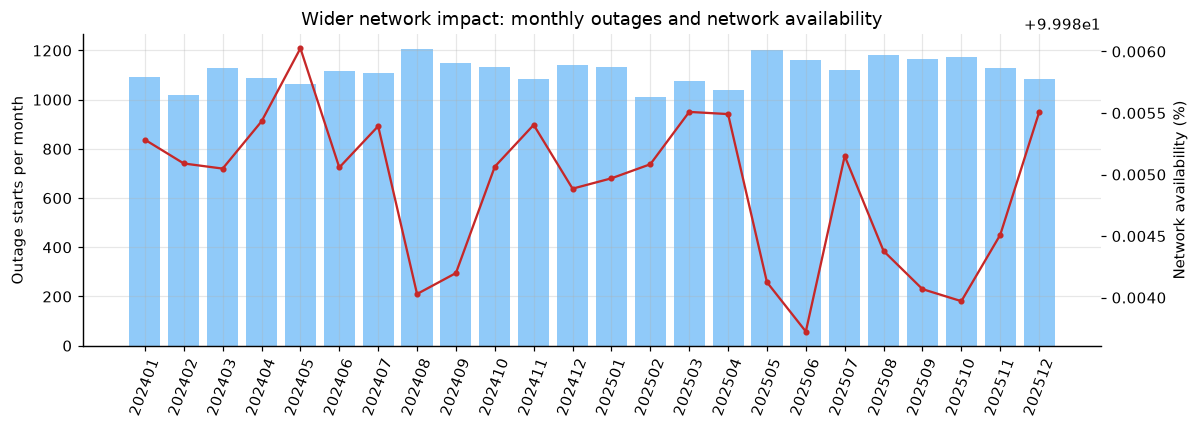

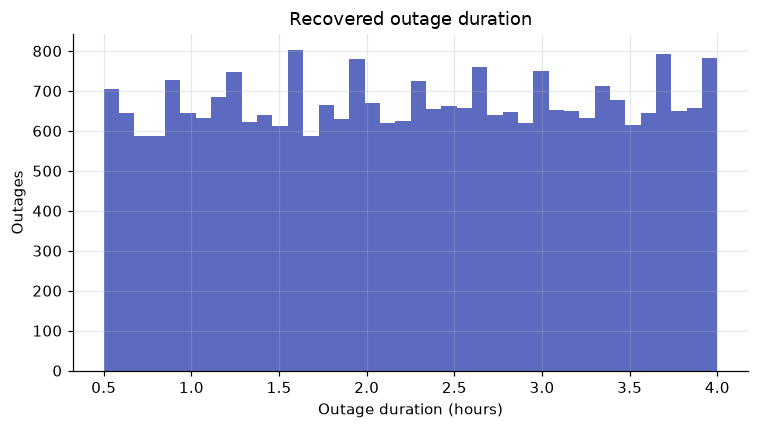

In [4]:
ev = EVENTS_RAW
o = ev[ev.Record_Type == "OUTAGE"].copy()
o["start"] = np.where(o.down_sec >= 0, o.down_sec, o.sec)
r = ev[ev.Record_Type == "RECOVERY"].copy()
r["end"] = np.where(r.up_sec >= 0, r.up_sec, r.sec)
dup_out = int(o.duplicated(["cell_idx", "start"]).sum())
dup_rec = int(r.duplicated(["cell_idx", "end"]).sum())
o = o.drop_duplicates(["cell_idx", "start"]).sort_values("start")
r = r.drop_duplicates(["cell_idx", "end"]).sort_values("end")
m = pd.merge_asof(o[["cell_idx", "start"]], r[["cell_idx", "end"]], left_on="start", right_on="end",
                  by="cell_idx", direction="forward", allow_exact_matches=True)
# a recovery can close only one outage: the next outage of the same cell must start after it
m = m.sort_values(["cell_idx", "start"])
nxt = m.groupby("cell_idx")["start"].shift(-1)
m.loc[m["end"].notna() & nxt.notna() & (m["end"] > nxt), "end"] = np.nan
m["recovered"] = m["end"].notna()
m["end"] = m["end"].fillna(DATA_END + 1).astype(np.int64)
m["duration_h"] = (m["end"] - m["start"]) / H
OUT = m.reset_index(drop=True)
OUT["site_idx"] = CELL_SITE[OUT.cell_idx]
OUT["Technology"] = CELL_TECH[OUT.cell_idx]
OUT["Region"] = d1["Region"].to_numpy()[OUT.cell_idx]
OUT["District"] = d1["District"].to_numpy()[OUT.cell_idx]
dt_start = sec_to_dt(OUT.start)
OUT["month"] = dt_start.year * 100 + dt_start.month
OUT["Season"] = dt_start.month.map(SEASON_OF_MONTH)
OUT["oid"] = np.arange(len(OUT))

ev_summary = {"outage_events": len(OUT), "duplicate_outage_events_removed": dup_out,
              "duplicate_recovery_events_removed": dup_rec, "recovered_outages": int(OUT.recovered.sum()),
              "unrecovered_outages": int((~OUT.recovered).sum()), "cells_with_outage": int(OUT.cell_idx.nunique()),
              "duration_mean_h": round(OUT.loc[OUT.recovered, "duration_h"].mean(), 3),
              "duration_median_h": round(OUT.loc[OUT.recovered, "duration_h"].median(), 3),
              "duration_min_h": round(OUT.loc[OUT.recovered, "duration_h"].min(), 3),
              "duration_max_h": round(OUT.loc[OUT.recovered, "duration_h"].max(), 3)}
RESULTS["outage_events"] = ev_summary
savetab(pd.DataFrame(ev_summary.items(), columns=["Measure", "Value"]), "rq2_outage_event_summary")

# ---- availability
OBS_H = (DATA_END - DATA_START) / H
down_h = (np.minimum(OUT["end"], DATA_END) - OUT["start"]).clip(lower=0) / H
OUT["down_h"] = down_h
avail_all = 100 * (1 - down_h.sum() / (N_CELLS * OBS_H))
rows = [("All cells", N_CELLS, down_h.sum(), avail_all)]
for t in TECHS:
    n = int((CELL_TECH == t).sum())
    dh = OUT.loc[OUT.Technology == t, "down_h"].sum()
    rows.append((t, n, dh, 100 * (1 - dh / (n * OBS_H))))
avail_tab = pd.DataFrame(rows, columns=["Group", "Cells", "Downtime_cell_hours", "Availability_pct"])
avail_tab["Availability_pct"] = avail_tab["Availability_pct"].round(4)
savetab(avail_tab, "rq2_network_availability_by_technology")
RESULTS["network_availability_pct"] = round(float(avail_all), 4)

months = pd.period_range(sec_to_dt([DATA_START])[0], sec_to_dt([DATA_END])[0], freq="M")
mon = OUT.groupby("month").agg(Outages=("oid", "size"), Downtime_h=("down_h", "sum")).reindex(
    [p.year * 100 + p.month for p in months], fill_value=0)
mon["Hours_in_month"] = [p.days_in_month * 24 for p in months]
mon["Availability_pct"] = 100 * (1 - mon.Downtime_h / (N_CELLS * mon.Hours_in_month))
mon = mon.reset_index().rename(columns={"index": "month"})
mon["Season"] = (mon["month"] % 100).map(SEASON_OF_MONTH)
savetab(mon.round(4), "rq2_monthly_outages_availability", show=False)
season_av = mon.groupby("Season").agg(Outages=("Outages", "sum"), Downtime_h=("Downtime_h", "sum"),
                                      Hours=("Hours_in_month", "sum")).reset_index()
season_av["Availability_pct"] = (100 * (1 - season_av.Downtime_h / (N_CELLS * season_av.Hours))).round(4)
savetab(season_av, "rq2_availability_by_season")

fig, ax1 = plt.subplots(figsize=(11, 4))
lbl = [str(x) for x in mon["month"]]
ax1.bar(lbl, mon.Outages, color="#90caf9", label="Outage starts")
ax1.set_ylabel("Outage starts per month"); ax1.tick_params(axis="x", rotation=70)
ax2 = ax1.twinx(); ax2.plot(lbl, mon.Availability_pct, color="#c62828", marker="o", ms=3, label="Availability")
ax2.set_ylabel("Network availability (%)"); ax2.grid(False)
ax1.set_title("Wider network impact: monthly outages and network availability")
savefig("rq2_monthly_outages_availability")

plt.figure(figsize=(7, 4))
plt.hist(OUT.loc[OUT.recovered, "duration_h"], bins=40, color="#5c6bc0")
plt.xlabel("Outage duration (hours)"); plt.ylabel("Outages"); plt.title("Recovered outage duration")
savefig("rq2_outage_duration_hist")

## 4. Evaluation design (split) and leakage-safe event lookups
* **Train:** all of 2024, seen sites only — every positive row + 1 % of negative rows.
* **Validation:** Feb, Jun, Oct 2025 (first month of each project-defined period) — every row of a random 5 % of seen-site cells.
* **Temporal test:** Mar, Jul, Nov 2025 — the same 5 % of cells.
* **Unseen-site test:** Mar, Jul, Nov 2025 — every row of **2,000 randomly selected sites** (seed 42) never used in
  training or validation (random, not the last 2,000 IDs, which are ordered by district code).

Event-based quantities are computed with sorted **key arrays** (`key = cell × 10⁹ + seconds`) and binary search, so
labels and history/neighbor features use only the event *times* and never future KPI values.

In [5]:
rng = np.random.default_rng(SEED)
n_unseen = min(N_UNSEEN_SITES, N_SITES // 3)
unseen_sites = rng.choice(N_SITES, size=n_unseen, replace=False)
SITE_UNSEEN = np.zeros(N_SITES, bool); SITE_UNSEEN[unseen_sites] = True
seen_cells = np.where(~SITE_UNSEEN[CELL_SITE])[0]
eval_cells = rng.choice(seen_cells, size=max(1, round(EVAL_CELL_SHARE * len(seen_cells))), replace=False)
unseen_cells = np.where(SITE_UNSEEN[CELL_SITE])[0]
unseen_keep = rng.choice(unseen_cells, size=max(1, round(UNSEEN_CELL_SHARE * len(unseen_cells))), replace=False)
CELL_ROLE = np.zeros(N_CELLS, np.int8)       # 0 seen (train only), 1 seen eval cell, 2 unseen kept, 3 unseen dropped
CELL_ROLE[eval_cells] = 1
CELL_ROLE[unseen_cells] = 3
CELL_ROLE[unseen_keep] = 2
print(f"Unseen sites: {n_unseen:,} | eval cells (val/temporal test): {len(eval_cells):,} | unseen-site test cells: {len(unseen_keep):,}")

def make_keys(cell, sec):
    return np.asarray(cell, np.int64) * BIG + (np.asarray(sec, np.int64) - T0)

OWN_START = np.sort(make_keys(OUT.cell_idx, OUT.start))
def _explode(recipients):
    c, s, e = [], [], []
    for ci, st, en, rec in zip(OUT.cell_idx.to_numpy(), OUT.start.to_numpy(), OUT.end.to_numpy(), recipients):
        if len(rec):
            c.append(rec); s.append(np.full(len(rec), st)); e.append(np.full(len(rec), en))
    if not c:
        return np.array([], np.int64), np.array([], np.int64)
    c, s, e = np.concatenate(c), np.concatenate(s), np.concatenate(e)
    return np.sort(make_keys(c, s)), np.sort(make_keys(c, e))
# neighbor events: an outage of cell c is a "neighbor outage" for every cell that lists c as neighbor
NBR_START, NBR_END = _explode([REV_NBR[c] for c in OUT.cell_idx])
SITE_START, SITE_END = _explode([SITE_CELLS[CELL_SITE[c]][SITE_CELLS[CELL_SITE[c]] != c] for c in OUT.cell_idx])

def count_between(keys, cell, sec, lo_h, hi_h):
    """Events with time in (t + lo_h, t + hi_h] for each row."""
    k = make_keys(cell, sec)
    return (np.searchsorted(keys, k + int(hi_h * H), "right") - np.searchsorted(keys, k + int(lo_h * H), "right"))

def count_active(start_keys, end_keys, cell, sec):
    """Intervals with start <= t < end (e.g., neighbors down now)."""
    base = np.asarray(cell, np.int64) * BIG
    k = make_keys(cell, sec)
    n_s = np.searchsorted(start_keys, k, "right") - np.searchsorted(start_keys, base, "left")
    n_e = np.searchsorted(end_keys, k, "right") - np.searchsorted(end_keys, base, "left")
    return n_s - n_e

def own_history(cell, sec):
    base = np.asarray(cell, np.int64) * BIG
    k = make_keys(cell, sec)
    i_le = np.searchsorted(OWN_START, k, "right")
    prev_cnt = i_le - np.searchsorted(OWN_START, base, "left")
    last_key = OWN_START[np.clip(i_le - 1, 0, len(OWN_START) - 1)] if len(OWN_START) else np.zeros_like(k)
    hrs_since = np.where(prev_cnt > 0, (k - last_key) / H, (np.asarray(sec) - DATA_START) / H)
    nxt = OWN_START[np.clip(i_le, 0, len(OWN_START) - 1)] if len(OWN_START) else np.zeros_like(k)
    has_next = (i_le < len(OWN_START)) & (nxt // BIG == np.asarray(cell, np.int64)) if len(OWN_START) else np.zeros(len(k), bool)
    next_sec = np.where(has_next, nxt % BIG + T0, -1)
    return prev_cnt, hrs_since, next_sec

Unseen sites: 2,000 | eval cells (val/temporal test): 764 | unseen-site test cells: 7,629


### 4.1 Windows collected during Pass B for the impact (RQ2) and pre-outage (RQ3) analyses
* **Service impact:** the affected cell's last KPI record in the 3 h before every outage.
* **RQ3 pre-outage test:** 2,000 random outages — own cell in the 12 h before the outage vs. the same clock hours 7 days earlier.
* **RQ2 neighbor impact:** 500 random outages — every mapped neighbor from 6 h before to 6 h after the outage start, and the same
  hours 7 days earlier (difference-in-differences).

In [6]:
WEEK = 7 * 24 * H
ok_hist = OUT.start - WEEK - 12 * H >= DATA_START
pre_sample = OUT[ok_hist].sample(n=min(N_PRE_OUTAGE_SAMPLE, int(ok_hist.sum())), random_state=SEED)
nbr_pool = OUT[ok_hist & (OUT.start + 6 * H <= DATA_END)]
nbr_sample = nbr_pool.sample(n=min(N_NEIGHBOR_SAMPLE, len(nbr_pool)), random_state=SEED + 1)

win = [pd.DataFrame({"cell": OUT.cell_idx, "lo": OUT.start - 3 * H, "hi": OUT.start})]
for off in [0, WEEK]:
    win.append(pd.DataFrame({"cell": pre_sample.cell_idx, "lo": pre_sample.start - off - 12 * H, "hi": pre_sample.start - off}))
nbr_pairs = pd.DataFrame([(row.oid, row.cell_idx, n, row.start) for row in nbr_sample.itertuples() for n in NBR[row.cell_idx]],
                         columns=["oid", "src", "nbr", "start"])
nbr_pairs["same_site"] = CELL_SITE[nbr_pairs.nbr] == CELL_SITE[nbr_pairs.src]
for off in [0, WEEK]:
    win.append(pd.DataFrame({"cell": nbr_pairs.nbr, "lo": nbr_pairs.start - off - 6 * H, "hi": nbr_pairs.start - off + 6 * H}))
    win.append(pd.DataFrame({"cell": nbr_sample.cell_idx, "lo": nbr_sample.start - off - 6 * H, "hi": nbr_sample.start - off}))
win = pd.concat(win, ignore_index=True)
win_lo, win_hi = make_keys(win.cell, win.lo), make_keys(win.cell, win.hi)
o_ = np.argsort(win_lo)
WIN_LO, WIN_HI_MAX = win_lo[o_], np.maximum.accumulate(win_hi[o_])

def in_windows(cell, sec):
    k = make_keys(cell, sec)
    i = np.searchsorted(WIN_LO, k, "right") - 1
    return (i >= 0) & (k < WIN_HI_MAX[np.clip(i, 0, None)])
print(f"Windows: {len(win):,} | RQ3 outages: {len(pre_sample):,} | RQ2 outage-neighbor pairs: {len(nbr_pairs):,}")

Windows: 41,763 | RQ3 outages: 2,000 | RQ2 outage-neighbor pairs: 4,977


## 5. RQ1 — Leakage-safe feature engineering and target construction (Pass B)
For every KPI record of cell *c* at time *t* (a cell that is down has no KPI record, so it is not a prediction row):

| Group | Features (only information available at *t*) |
|---|---|
| KPI (6-h lookback) | current value, lag 1 & lag 2 (previous two 3-hourly records), mean of the 3 records, trend = (current − lag 2)/2, for Traffic, Connected_Users, Throughput, Latency, Packet_Loss, Load, Alarm_Count, **Utilization = Load/Capacity×100**; Capacity; hours since previous record |
| Outage history | outages started before *t* (`Prev_Outages`), outages in the last 7 days, hours since the last outage start |
| Calendar / context | hour, day of week, month, project season, Technology, Region, neighbor count, cells on site |
| **RQ5 neighbor** | outage starts among mapped neighbors and among same-site cells in (t − 6 h, t]; neighbors and same-site cells down at *t* |

**Target** `Outage_Next_12h = 1` if the same cell has a new OUTAGE start in (t, t + 12 h]; rows whose 12-h horizon passes the end of
the data are removed. `Cell_Down_Time`, `Cell_Up_Time`, `Record_Type`, `Status`, future KPIs and Availability are **never features**.
Invalid KPI values (boundary rules) are set to missing and imputed later with training-only medians.

In [7]:
SEL_KPI = ["Traffic", "Connected_Users", "Throughput", "Latency", "Packet_Loss", "Load", "Capacity", "Alarm_Count"]
SPLIT_CODE = {"train": 0, "val": 1, "test_temporal": 2, "test_unseen": 3}

def pass_b():
    carry = None
    parts, impact_parts = [], []
    elig = {s: [0, 0] for s in SPLIT_CODE}        # rows and positives before sampling
    rs = np.random.default_rng(SEED + 7)
    t_start = time.time()
    for k, ch in enumerate(read_d2()):
        ch = ch[ch["Record_Type"].str.strip().str.upper() == "KPI"]
        sec = to_sec(ch["Timestamp"])
        cell = CELL_INDEX.get_indexer(ch["Cell_ID"].str.strip())
        ok = (sec >= 0) & (cell >= 0)
        X = {c: ch[c].to_numpy(np.float32)[ok] for c in SEL_KPI}
        sec, cell = sec[ok], cell[ok]
        for c in ["Traffic", "Connected_Users", "Throughput", "Latency"]:
            X[c][X[c] < 0] = np.nan
        X["Packet_Loss"][(X["Packet_Loss"] < 0) | (X["Packet_Loss"] > 100)] = np.nan
        X["Capacity"][X["Capacity"] <= 0] = np.nan
        X["Utilization"] = (X["Load"] / X["Capacity"] * 100).astype(np.float32)
        # ---- impact / pre-outage windows (raw KPI rows)
        w = in_windows(cell, sec)
        if w.any():
            impact_parts.append(pd.DataFrame({"cell": cell[w], "sec": sec[w], **{c: X[c][w] for c in SEL_KPI + ["Utilization"]}}))
        # ---- lags within cell (carry the last two records of each cell across chunks)
        cur = pd.DataFrame({"cell": cell, "sec": sec, "is_carry": False, **{c: X[c] for c in SEL_KPI + ["Utilization"]}})
        comb = pd.concat([carry, cur], ignore_index=True) if carry is not None else cur
        comb = comb.sort_values(["cell", "sec"], kind="stable").reset_index(drop=True)
        cc = comb["cell"].to_numpy()
        s1 = np.r_[False, cc[1:] == cc[:-1]]
        s2 = np.r_[False, False, cc[2:] == cc[:-2]]
        F = {}
        for c in LAG_COLS:
            v = comb[c].to_numpy(np.float32)
            l1 = np.where(s1, np.r_[np.nan, v[:-1]], np.nan).astype(np.float32)
            l2 = np.where(s2, np.r_[np.nan, np.nan, v[:-2]], np.nan).astype(np.float32)
            F[c] = v; F[f"{c}_lag1"] = l1; F[f"{c}_lag2"] = l2
            F[f"{c}_mean6h"] = np.nanmean(np.vstack([v, l1, l2]), axis=0).astype(np.float32)
            F[f"{c}_trend"] = ((v - l2) / 2).astype(np.float32)
        F["Capacity"] = comb["Capacity"].to_numpy(np.float32)
        ss = comb["sec"].to_numpy(np.int64)
        F["Hours_Since_Prev_Record"] = np.where(s1, (ss - np.r_[0, ss[:-1]]) / H, np.nan).astype(np.float32)
        last2 = ~np.r_[cc[2:] == cc[:-2], False, False]
        carry = comb.loc[last2, ["cell", "sec"] + SEL_KPI + ["Utilization"]].assign(is_carry=True)
        keep = ~comb["is_carry"].to_numpy()
        F = {c: v[keep] for c, v in F.items()}
        cc, ss = cc[keep], ss[keep]
        # ---- target, history, neighbor features (event times only)
        y = (count_between(OWN_START, cc, ss, 0, HORIZON_H) > 0).astype(np.int8)
        prev_cnt, hrs_since, next_sec = own_history(cc, ss)
        dt = sec_to_dt(ss)
        ym = (dt.year * 100 + dt.month).to_numpy()
        horizon_ok = ss + HORIZON_H * H <= DATA_END
        role = CELL_ROLE[cc]
        split = np.full(len(cc), -1, np.int8)
        tr = horizon_ok & (dt.year.to_numpy() == TRAIN_YEAR) & (role <= 1)
        va = horizon_ok & np.isin(ym, VAL_MONTHS) & (role == 1)
        tt = horizon_ok & np.isin(ym, TEST_MONTHS) & (role == 1)
        tu = horizon_ok & np.isin(ym, TEST_MONTHS) & (role == 2)
        for name, msk in [("train", tr), ("val", va), ("test_temporal", tt), ("test_unseen", tu)]:
            elig[name][0] += int(msk.sum()); elig[name][1] += int(y[msk].sum())
        tr_keep = tr & ((y == 1) | (rs.random(len(cc)) < TRAIN_NEG_RATE))
        split[tr_keep] = 0; split[va] = 1; split[tt] = 2; split[tu] = 3
        sel = split >= 0
        if sel.any():
            c_, s_ = cc[sel], ss[sel]
            df = pd.DataFrame({c: v[sel] for c, v in F.items()})
            df["Prev_Outages"] = prev_cnt[sel].astype(np.float32)
            df["Outages_Last_7d"] = count_between(OWN_START, c_, s_, -7 * 24, 0).astype(np.float32)
            df["Hours_Since_Last_Outage"] = hrs_since[sel].astype(np.float32)
            df["Hour"] = dt.hour.to_numpy()[sel].astype(np.float32)
            df["DayOfWeek"] = dt.dayofweek.to_numpy()[sel].astype(np.float32)
            df["Month"] = dt.month.to_numpy()[sel].astype(np.float32)
            df["Nbr_Outage_Starts_6h"] = count_between(NBR_START, c_, s_, -LOOKBACK_H, 0).astype(np.float32)
            df["Site_Outage_Starts_6h"] = count_between(SITE_START, c_, s_, -LOOKBACK_H, 0).astype(np.float32)
            df["Nbr_Down_Now"] = count_active(NBR_START, NBR_END, c_, s_).astype(np.float32)
            df["Site_Down_Now"] = count_active(SITE_START, SITE_END, c_, s_).astype(np.float32)
            df["cell"] = c_.astype(np.int32); df["sec"] = s_; df["ym"] = ym[sel].astype(np.int32)
            df["split"] = split[sel]; df["y"] = y[sel]; df["next_outage_sec"] = next_sec[sel]
            parts.append(df)
        if k % 10 == 0:
            print(f"  chunk {k:4d}: {sum(len(p) for p in parts):>11,} model rows kept  ({time.time() - t_start:6.0f} s)")
    data = pd.concat(parts, ignore_index=True)
    impact = pd.concat(impact_parts, ignore_index=True) if impact_parts else pd.DataFrame()
    return data, impact, elig

cache_b = CACHE_DIR / f"pass_b_{DATA_TAG}.pkl"
if USE_CACHE and cache_b.exists():
    DATA, IMPACT_ROWS, ELIG = pickle.load(open(cache_b, "rb"))
    print("Loaded Pass B from cache.")
else:
    DATA, IMPACT_ROWS, ELIG = pass_b()
    pickle.dump((DATA, IMPACT_ROWS, ELIG), open(cache_b, "wb"), protocol=4)
print("Model-ready rows:", f"{len(DATA):,}", "| impact-window KPI rows:", f"{len(IMPACT_ROWS):,}")

# static context features
DATA["Neighbor_Count"] = d1["Neighbor_Count"].to_numpy()[DATA.cell].astype(np.float32)
DATA["Cells_On_Site"] = d1["Cells_On_Site"].to_numpy()[DATA.cell].astype(np.float32)
for t in TECHS:
    DATA[f"Tech_{t}"] = (CELL_TECH[DATA.cell] == t).astype(np.float32)
reg = d1["Region"].to_numpy()
for g in REGIONS:
    DATA[f"Region_{g}"] = (reg[DATA.cell] == g).astype(np.float32)
for s in ["Summer", "Rainy", "Winter"]:
    DATA[f"Season_{s}"] = (DATA["Month"].map(SEASON_OF_MONTH) == s).astype(np.float32)
DATA["site"] = CELL_SITE[DATA.cell]

Loaded Pass B from cache.
Model-ready rows: 7,201,898 | impact-window KPI rows: 81,970


### 5.1 Class balance (feedback item 3)
Positive rate **before** sampling for every split; training then keeps all positives and 1 % of negatives, while validation and
both test sets keep the true prevalence.

In [8]:
cb = []
for name, code in SPLIT_CODE.items():
    sub = DATA[DATA.split == code]
    cb.append({"Split": name, "Eligible_rows": ELIG[name][0], "Eligible_positives": ELIG[name][1],
               "Positive_rate_pct": round(100 * ELIG[name][1] / max(ELIG[name][0], 1), 4),
               "Rows_used": len(sub), "Positives_used": int(sub.y.sum()),
               "Positive_rate_used_pct": round(100 * sub.y.mean(), 4) if len(sub) else np.nan,
               "Cells": sub.cell.nunique(), "Sites": sub.site.nunique()})
class_balance = pd.DataFrame(cb)
savetab(class_balance, "rq4_class_balance")
RESULTS["class_balance"] = class_balance.to_dict(orient="records")

,Split,Eligible_rows,Eligible_positives,Positive_rate_pct,Rows_used,Positives_used,Positive_rate_used_pct,Cells,Sites
0,train,44706839,35474,0.0793,481716,35474,7.3641,15271,4000
1,val,543885,433,0.0796,543885,433,0.0796,764,711
2,test_temporal,562221,490,0.0872,562221,490,0.0872,764,711
3,test_unseen,5614076,4445,0.0792,5614076,4445,0.0792,7629,2000


## 6. RQ2 — Outage impact: affected cell (Service Impact) and neighboring cells (difference-in-differences)

,Technology,Outages,Mean_duration_h,Median_users_before,Total_user_hours_lost,Median_user_hours_per_outage,Total_traffic_not_served
0,2G,7284,2.25,51.0,898897.53,103.13,9523.24
1,3G,7131,2.28,67.0,1166634.52,135.53,23991.94
2,4G,6850,2.25,132.0,2214421.02,260.33,87748.48
3,5G,5533,2.28,182.0,2482304.98,356.22,164870.63
4,All,26798,2.26,84.0,6762258.05,175.15,286134.30


,Group,KPI,Pairs,Share_increased_pct,Median_DiD,Sign_test_p
0,All neighbors,Connected_Users,4875,63.0,3.500,2.665024e-74
1,All neighbors,Traffic,4976,63.5,0.266,4.853762e-82
2,All neighbors,Load,4977,65.6,2.111,4.936564e-109
3,All neighbors,Utilization,4977,65.6,4.792,4.936564e-109
4,All neighbors,Throughput,4969,39.2,-0.061,8.126254e-53
5,All neighbors,Latency,4977,68.3,4.594,3.651783e-150
6,All neighbors,Packet_Loss,4971,64.6,0.068,1.361791e-95
7,All neighbors,Alarm_Count,596,54.9,0.500,1.947725e-02


,Group,KPI,Pairs,Share_increased_pct,Median_DiD,Sign_test_p
0,Other-site neighbor,Connected_Users,3870,62.6,3.500,1.714429e-55
1,Other-site neighbor,Traffic,3942,63.0,0.246,4.034893e-60
2,Other-site neighbor,Load,3943,65.3,1.978,8.826644e-84
3,Other-site neighbor,Utilization,3943,65.3,4.562,8.826644e-84
4,Other-site neighbor,Throughput,3936,39.2,-0.062,7.566138e-42
5,Other-site neighbor,Latency,3943,68.1,4.579,2.085893e-117
6,Other-site neighbor,Packet_Loss,3938,64.2,0.065,2.443561e-72
7,Other-site neighbor,Alarm_Count,471,55.4,0.500,2.113071e-02
8,Same-site neighbor,Connected_Users,1005,64.7,3.500,9.505625e-21
9,Same-site neighbor,Traffic,1034,65.7,0.373,4.121652e-24


Median share of the failed cell's users absorbed by neighbors: 28.2 %


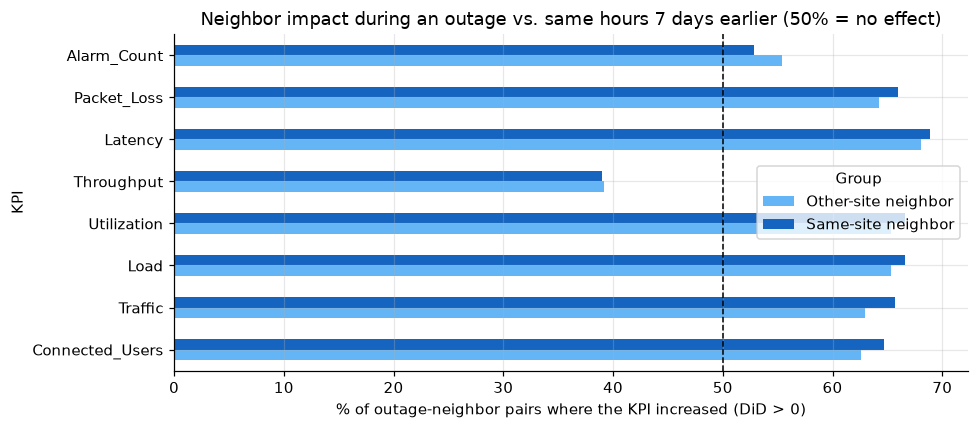

In [9]:
IR = IMPACT_ROWS.sort_values(["cell", "sec"]).reset_index(drop=True)

def window_stat(windows, how="median", cols=SEL_KPI + ["Utilization"]):
    """windows: DataFrame(wid, cell, lo, hi) -> aggregated KPI per window id (rows with lo <= sec < hi)."""
    j = windows.merge(IR, on="cell", how="inner")
    j = j[(j.sec >= j.lo) & (j.sec < j.hi)]
    return j.groupby("wid")[cols].agg(how)

# --- Service impact on the affected cell (all outages): users and traffic of the last record before the outage
w_serv = pd.DataFrame({"wid": OUT.oid, "cell": OUT.cell_idx, "lo": OUT.start - 3 * H, "hi": OUT.start})
pre_last = window_stat(w_serv, how="last", cols=["Connected_Users", "Traffic", "Throughput"])
serv = OUT[OUT.recovered].set_index("oid").join(pre_last, how="inner")
serv["User_Hours_Lost"] = serv.Connected_Users * serv.duration_h
serv["Traffic_Not_Served"] = serv.Traffic * serv.duration_h / KPI_STEP_H     # Traffic is per 3-hour record
serv_tab = serv.groupby("Technology").agg(Outages=("cell_idx", "size"), Mean_duration_h=("duration_h", "mean"),
                                          Median_users_before=("Connected_Users", "median"),
                                          Total_user_hours_lost=("User_Hours_Lost", "sum"),
                                          Median_user_hours_per_outage=("User_Hours_Lost", "median"),
                                          Total_traffic_not_served=("Traffic_Not_Served", "sum")).reset_index()
tot = serv.agg({"User_Hours_Lost": "sum", "Traffic_Not_Served": "sum"})
serv_tab.loc[len(serv_tab)] = ["All", len(serv), serv.duration_h.mean(), serv.Connected_Users.median(),
                               tot.User_Hours_Lost, serv.User_Hours_Lost.median(), tot.Traffic_Not_Served]
savetab(serv_tab.round(2), "rq2_service_impact_affected_cell")
RESULTS["service_impact_total_user_hours_lost"] = round(float(tot.User_Hours_Lost), 1)

# --- Neighbor difference-in-differences
NB_KPIS = ["Connected_Users", "Traffic", "Load", "Utilization", "Throughput", "Latency", "Packet_Loss", "Alarm_Count"]
nbr_pairs["pid"] = np.arange(len(nbr_pairs))
phases = {}
for name, lo, hi in [("pre", -6, 0), ("post", 0, 6), ("cpre", -6 - 168, -168), ("cpost", -168, 6 - 168)]:
    wdf = pd.DataFrame({"wid": nbr_pairs.pid, "cell": nbr_pairs.nbr, "lo": nbr_pairs.start + lo * H,
                        "hi": nbr_pairs.start + hi * H})
    phases[name] = window_stat(wdf, cols=NB_KPIS)
P = {k: v.reindex(nbr_pairs.pid) for k, v in phases.items()}
did = (P["post"] - P["pre"]) - (P["cpost"] - P["cpre"])
did = did.join(nbr_pairs.set_index("pid")[["oid", "src", "nbr", "same_site"]])
did["Nbr_Tech"] = CELL_TECH[did.nbr]
did = did.join(OUT.set_index("oid")[["duration_h"]], on="oid")
did["Duration_bucket"] = pd.cut(did.duration_h, [0, 1.5, 3, np.inf], labels=["<1.5 h", "1.5-3 h", ">3 h"])

def did_table(df, group=None):
    rows = []
    groups = [("All neighbors", df)] if group is None else [(g, d) for g, d in df.groupby(group, observed=True)]
    for g, d in groups:
        for c in NB_KPIS:
            x = d[c].dropna(); x = x[x != 0]
            if len(x) < 5:
                continue
            up = int((x > 0).sum())
            rows.append({"Group": g, "KPI": c, "Pairs": len(x), "Share_increased_pct": round(100 * up / len(x), 1),
                         "Median_DiD": round(float(x.median()), 3),
                         "Sign_test_p": stats.binomtest(up, len(x), 0.5).pvalue})
    return pd.DataFrame(rows)

did_all = did_table(did)
did_site = did_table(did.assign(Site=np.where(did.same_site, "Same-site neighbor", "Other-site neighbor")), "Site")
did_tech = did_table(did, "Nbr_Tech")
did_dur = did_table(did, "Duration_bucket")
savetab(did_all, "rq2_neighbor_did_all")
savetab(did_site, "rq2_neighbor_did_same_vs_other_site")
savetab(did_tech, "rq2_neighbor_did_by_technology", show=False)
savetab(did_dur, "rq2_neighbor_did_by_duration", show=False)

# share of the affected cell's users absorbed by its neighbors
own_pre = window_stat(pd.DataFrame({"wid": nbr_sample.oid, "cell": nbr_sample.cell_idx, "lo": nbr_sample.start - 6 * H,
                                    "hi": nbr_sample.start}), cols=["Connected_Users"])
absorbed = did.groupby("oid")["Connected_Users"].sum(min_count=1).to_frame("Nbr_user_increase").join(own_pre)
absorbed = absorbed[absorbed.Connected_Users > 0]
absorbed["Share_absorbed_pct"] = 100 * absorbed.Nbr_user_increase / absorbed.Connected_Users
RESULTS["neighbor_users_absorbed_median_pct"] = round(float(absorbed.Share_absorbed_pct.median()), 1) if len(absorbed) else None
print("Median share of the failed cell's users absorbed by neighbors:", RESULTS["neighbor_users_absorbed_median_pct"], "%")

fig, ax = plt.subplots(figsize=(9, 4))
pv = did_site.pivot(index="KPI", columns="Group", values="Share_increased_pct").reindex(NB_KPIS).dropna(how="all")
pv.plot(kind="barh", ax=ax, color=["#64b5f6", "#1565c0"])
ax.axvline(50, color="k", ls="--", lw=1); ax.set_xlabel("% of outage-neighbor pairs where the KPI increased (DiD > 0)")
ax.set_title("Neighbor impact during an outage vs. same hours 7 days earlier (50% = no effect)")
savefig("rq2_neighbor_did_share_increased")

## 7. RQ3 — Is there an early-warning signal? Matched-control test before outages
Own-cell KPIs in the 12 h before each sampled outage vs. the **same cell and clock hours 7 days earlier**: share of outages with a
higher pre-outage value (50 % = coin toss), median difference, and the Wilcoxon signed-rank test; also split by technology.

,Group,KPI,Outages,Share_higher_before_pct,Median_difference,Wilcoxon_p
0,All,Traffic,2000,49.8,-0.0013,0.899411
1,All,Connected_Users,2000,49.3,0.0000,0.379569
2,All,Throughput,2000,23.6,-0.1357,0.000000
3,All,Latency,2000,75.6,7.1883,0.000000
4,All,Packet_Loss,2000,74.9,0.1469,0.000000
5,All,Load,2000,64.4,0.9001,0.000000
6,All,Utilization,2000,64.4,2.3292,0.000000
7,All,Alarm_Count,2000,46.0,0.0000,0.000000


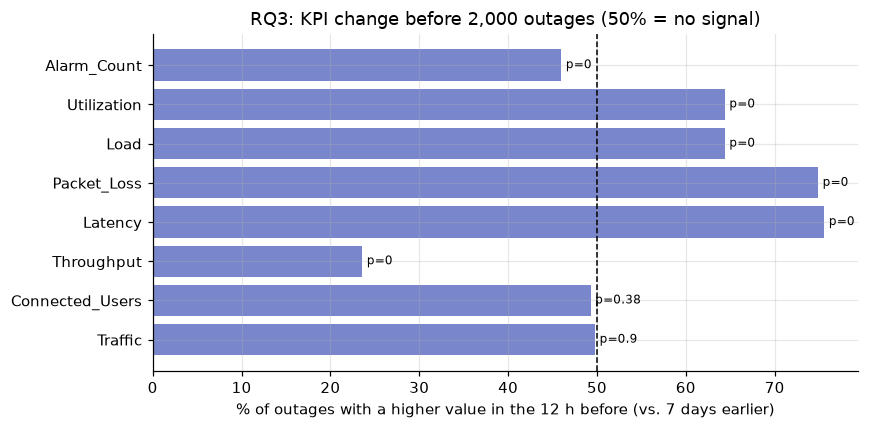

In [10]:
pre = window_stat(pd.DataFrame({"wid": pre_sample.oid, "cell": pre_sample.cell_idx, "lo": pre_sample.start - 12 * H,
                                "hi": pre_sample.start}), how="mean")
ctl = window_stat(pd.DataFrame({"wid": pre_sample.oid, "cell": pre_sample.cell_idx, "lo": pre_sample.start - WEEK - 12 * H,
                                "hi": pre_sample.start - WEEK}), how="mean")
diff = (pre - ctl).dropna(how="all").join(OUT.set_index("oid")[["Technology"]])
PRE_KPIS = ["Traffic", "Connected_Users", "Throughput", "Latency", "Packet_Loss", "Load", "Utilization", "Alarm_Count"]

def pre_table(df, label):
    rows = []
    for c in PRE_KPIS:
        x = df[c].dropna()
        nz = x[x != 0]
        p = stats.wilcoxon(nz).pvalue if len(nz) >= 10 else np.nan
        rows.append({"Group": label, "KPI": c, "Outages": len(x), "Share_higher_before_pct": round(100 * (x > 0).mean(), 1),
                     "Median_difference": round(float(x.median()), 4), "Wilcoxon_p": p})
    return pd.DataFrame(rows)

pre_all = pre_table(diff, "All")
pre_tech = pd.concat([pre_table(d, t) for t, d in diff.groupby("Technology")], ignore_index=True)
savetab(pre_all, "rq3_pre_outage_signal")
savetab(pre_tech, "rq3_pre_outage_signal_by_technology", show=False)
RESULTS["rq3_min_wilcoxon_p"] = float(np.nanmin(pre_all.Wilcoxon_p)) if len(pre_all) else None
RESULTS["rq3_share_higher_range_pct"] = [float(pre_all.Share_higher_before_pct.min()), float(pre_all.Share_higher_before_pct.max())]

plt.figure(figsize=(8, 4))
plt.barh(pre_all.KPI, pre_all.Share_higher_before_pct, color="#7986cb")
plt.axvline(50, color="k", ls="--", lw=1)
for i, (s, p) in enumerate(zip(pre_all.Share_higher_before_pct, pre_all.Wilcoxon_p)):
    plt.text(s + 0.5, i, f"p={p:.2g}", va="center", fontsize=8)
plt.xlabel("% of outages with a higher value in the 12 h before (vs. 7 days earlier)")
plt.title(f"RQ3: KPI change before {len(diff):,} outages (50% = no signal)")
savefig("rq3_pre_outage_signal")

## 8. Feature sets
* **Full (base)** = KPI 6-h lookback + Utilization + outage history + calendar/context (proposal + progress report feature space).
* **Full + Neighbor** = base + four RQ5 neighbor/same-site features.
* Ablations (best model family only): **KPI-only** and **No-KPI** (history + calendar/context) to locate where any signal comes from.

In [11]:
KPI_FEATS = [c for c in DATA.columns if any(c == k or c.startswith(k + "_") for k in LAG_COLS)] + ["Capacity", "Hours_Since_Prev_Record"]
HIST_FEATS = ["Prev_Outages", "Outages_Last_7d", "Hours_Since_Last_Outage"]
CAL_FEATS = ["Hour", "DayOfWeek", "Month"] + [c for c in DATA.columns if c.startswith(("Season_", "Tech_", "Region_"))] + \
            ["Neighbor_Count", "Cells_On_Site"]
NBR_FEATS = ["Nbr_Outage_Starts_6h", "Site_Outage_Starts_6h", "Nbr_Down_Now", "Site_Down_Now"]
FEATURE_SETS = {"Full": KPI_FEATS + HIST_FEATS + CAL_FEATS, "Full+Neighbor": KPI_FEATS + HIST_FEATS + CAL_FEATS + NBR_FEATS,
                "KPI-only": KPI_FEATS, "No-KPI": HIST_FEATS + CAL_FEATS}
FEATURE_GROUP = {**{f: "KPI lookback" for f in KPI_FEATS}, **{f: "Outage history" for f in HIST_FEATS},
                 **{f: "Calendar/context" for f in CAL_FEATS}, **{f: "Neighbor/same-site" for f in NBR_FEATS}}
print({k: len(v) for k, v in FEATURE_SETS.items()})

TR, VA = DATA[DATA.split == 0], DATA[DATA.split == 1]
TT, TU = DATA[DATA.split == 2], DATA[DATA.split == 3]
EVAL_SETS = {"Validation": VA, "Temporal test": TT, "Unseen-site test": TU}
N_MODEL_ROWS = len(DATA)
del DATA                       # free memory: the four split tables are all that is needed from here on
import gc; gc.collect()
# prior correction: training negatives were kept at TRAIN_NEG_RATE, so true odds = model odds x TRAIN_NEG_RATE
def calibrate(p):
    odds = p / np.clip(1 - p, 1e-9, None) * TRAIN_NEG_RATE
    return odds / (1 + odds)

{'Full': 61, 'Full+Neighbor': 65, 'KPI-only': 42, 'No-KPI': 19}


## 9. RQ4 — Models: rule baselines, Logistic Regression baseline, Decision Tree, Random Forest, Gradient Boosting
* **Rule baselines** (current operational practice): warning when `Alarm_Count` or `Utilization` ≥ threshold.
* **Logistic Regression (baseline ML model)** — median imputation + standardization fitted on training data only.
* **Decision Tree** (proposal comparison model), **Random Forest** (proposal main model), **Gradient Boosting**
  (HistGradientBoosting; added in the progress report's next steps as a third model family).

Hyper-parameters are chosen by **validation PR-AUC**; each model's decision threshold is chosen on validation to maximize F1
(down-sampling shifts probabilities). No test data is used for any choice.

In [12]:
def make_model(name, params):
    if name == "Logistic Regression":
        return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                         ("clf", LogisticRegression(max_iter=3000, **params))])
    if name == "Decision Tree":
        return Pipeline([("imp", SimpleImputer(strategy="median")),
                         ("clf", DecisionTreeClassifier(random_state=SEED, **params))])
    if name == "Random Forest":
        return Pipeline([("imp", SimpleImputer(strategy="median")),
                         ("clf", RandomForestClassifier(n_estimators=200, max_features="sqrt", n_jobs=-1,
                                                        random_state=SEED, **params))])
    if name == "Gradient Boosting":
        return HistGradientBoostingClassifier(max_iter=300, early_stopping=True, random_state=SEED, **params)

GRIDS = {"Logistic Regression": [{"C": c} for c in [0.01, 0.1, 1.0]],
         "Decision Tree": [{"max_depth": d, "min_samples_leaf": 200} for d in [4, 6, 8]],
         "Random Forest": [{"max_depth": d, "min_samples_leaf": l} for d in [8, 14] for l in [50]],
         "Gradient Boosting": [{"learning_rate": lr, "max_leaf_nodes": n} for lr in [0.05, 0.1] for n in [15, 31]]}

def predict_batched(model, X, bs=500_000):
    return np.concatenate([model.predict_proba(X.iloc[i:i + bs])[:, 1] for i in range(0, len(X), bs)]) if len(X) else np.array([])

def best_f1_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    i = int(np.nanargmax(f1[:-1])) if len(t) else 0
    return float(t[i]) if len(t) else 0.5

FITTED, SCORES, FIT_LOG = {}, {}, []
def fit_family(name, fset):
    feats = FEATURE_SETS[fset]
    best = None
    for params in GRIDS[name]:
        mdl = make_model(name, params)
        t0 = time.time(); mdl.fit(TR[feats], TR.y); fit_s = time.time() - t0
        sv = predict_batched(mdl, VA[feats])
        ap = average_precision_score(VA.y, sv) if VA.y.sum() else np.nan
        FIT_LOG.append({"Model": name, "Features": fset, "Params": str(params), "Val_PR_AUC": ap, "Fit_seconds": round(fit_s, 1)})
        if best is None or (ap > best[0]):
            best = (ap, params, mdl, fit_s, sv)
    ap, params, mdl, fit_s, sv = best
    thr = best_f1_threshold(VA.y, sv)
    t0 = time.time(); scores = {"Validation": sv}
    for es in ["Temporal test", "Unseen-site test"]:
        scores[es] = predict_batched(mdl, EVAL_SETS[es][feats])
    pred_s = (time.time() - t0) / max(len(TT) + len(TU), 1) * 1e6
    FITTED[(name, fset)] = {"model": mdl, "params": params, "thr": thr, "fit_s": fit_s, "pred_s_per_1M": pred_s, "feats": feats}
    SCORES[(name, fset)] = scores
    print(f"{name:20s} [{fset:13s}] best {params}  val PR-AUC={ap:.5f}  thr={thr:.4f}  fit={fit_s:.0f}s")

for fset in ["Full", "Full+Neighbor"]:
    for name in GRIDS:
        fit_family(name, fset)
savetab(pd.DataFrame(FIT_LOG), "rq4_hyperparameter_search", show=False)

# rule baselines: tuned on validation (score = raw current KPI value)
RULES = {"Rule: Alarm_Count": "Alarm_Count", "Rule: Utilization": "Utilization"}
for rname, col in RULES.items():
    sv = VA[col].fillna(-1).to_numpy()
    thr = best_f1_threshold(VA.y, sv)
    FITTED[(rname, "Full")] = {"model": None, "params": {"threshold": thr}, "thr": thr, "fit_s": 0.0,
                               "pred_s_per_1M": 0.0, "feats": [col]}
    SCORES[(rname, "Full")] = {es: EVAL_SETS[es][col].fillna(-1).to_numpy() for es in EVAL_SETS}
    print(f"{rname}: warn when {col} >= {thr:.3f}")

Logistic Regression  [Full         ] best {'C': 1.0}  val PR-AUC=0.01928  thr=0.7438  fit=5s
Decision Tree        [Full         ] best {'max_depth': 8, 'min_samples_leaf': 200}  val PR-AUC=0.04759  thr=0.9452  fit=22s
Random Forest        [Full         ] best {'max_depth': 14, 'min_samples_leaf': 50}  val PR-AUC=0.10304  thr=0.6967  fit=428s
Gradient Boosting    [Full         ] best {'learning_rate': 0.05, 'max_leaf_nodes': 31}  val PR-AUC=0.12939  thr=0.8660  fit=74s
Logistic Regression  [Full+Neighbor] best {'C': 1.0}  val PR-AUC=0.02333  thr=0.7611  fit=9s
Decision Tree        [Full+Neighbor] best {'max_depth': 8, 'min_samples_leaf': 200}  val PR-AUC=0.04759  thr=0.9452  fit=40s
Random Forest        [Full+Neighbor] best {'max_depth': 14, 'min_samples_leaf': 50}  val PR-AUC=0.09940  thr=0.7239  fit=419s
Gradient Boosting    [Full+Neighbor] best {'learning_rate': 0.1, 'max_leaf_nodes': 15}  val PR-AUC=0.12613  thr=0.7842  fit=55s
Rule: Alarm_Count: warn when Alarm_Count >= 3.000
Rule:

## 10. Model evaluation results (guideline item 6)
Metrics suited to rare events (accuracy is not used — predicting "no outage" always would be ~99.9 % accurate):
**PR-AUC** (average precision) and **lift = PR-AUC / positive rate** (1.0 = random guessing), ROC-AUC, precision, recall, F1 and the
confusion matrix at the validation-tuned threshold, **false alarms per site-day**, event-level **detection recall** and **median
warning lead time** (hours between the first alert and the outage start), and **calibration** (Brier score after prior correction).

In [13]:
def evaluate(name, fset, es):
    df, s, thr = EVAL_SETS[es], SCORES[(name, fset)][es], FITTED[(name, fset)]["thr"]
    y = df.y.to_numpy(); pred = s >= thr
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    prev = y.mean() if len(y) else np.nan
    ap = average_precision_score(y, s) if y.sum() else np.nan
    site_days = df.groupby(["site", df.sec // 86400]).ngroups
    pos = df.loc[y == 1, ["cell", "next_outage_sec", "sec"]].assign(alert=pred[y == 1])
    events_ = pos.groupby(["cell", "next_outage_sec"]).size().index
    first_alert = pos[pos.alert].groupby(["cell", "next_outage_sec"]).sec.min().reindex(events_)
    ev_ = pd.Series((events_.get_level_values(1) - first_alert.to_numpy()) / H, dtype=float) if len(events_) else pd.Series(dtype=float)
    out = {"Model": name, "Features": fset, "Eval set": es, "Rows": len(y), "Positives": int(y.sum()),
           "Positive_rate_pct": 100 * prev, "PR_AUC": ap, "Lift_vs_random": ap / prev if prev else np.nan,
           "ROC_AUC": roc_auc_score(y, s) if 0 < y.sum() < len(y) else np.nan,
           "Precision": tp / (tp + fp) if tp + fp else 0.0, "Recall": tp / (tp + fn) if tp + fn else 0.0,
           "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
           "False_alarms_per_site_day": fp / site_days if site_days else np.nan,
           "Outage_events": int(len(ev_)), "Events_detected": int(ev_.notna().sum()),
           "Event_detection_recall": ev_.notna().mean() if len(ev_) else np.nan,
           "Median_lead_time_h": float(ev_.median()) if ev_.notna().any() else np.nan}
    out["F1"] = 2 * out["Precision"] * out["Recall"] / (out["Precision"] + out["Recall"]) if out["Precision"] + out["Recall"] else 0.0
    out["Brier_calibrated"] = brier_score_loss(y, calibrate(s)) if FITTED[(name, fset)]["model"] is not None and len(y) else np.nan
    return out

rows = []
for (name, fset) in FITTED:
    for es in EVAL_SETS:
        rows.append(evaluate(name, fset, es))
for es, df in EVAL_SETS.items():
    prev = df.y.mean()
    rows.append({"Model": "Random guess", "Features": "-", "Eval set": es, "Rows": len(df), "Positives": int(df.y.sum()),
                 "Positive_rate_pct": 100 * prev, "PR_AUC": prev, "Lift_vs_random": 1.0, "ROC_AUC": 0.5})
RES = pd.DataFrame(rows)
cols_show = ["Model", "Features", "Eval set", "Positives", "Positive_rate_pct", "PR_AUC", "Lift_vs_random", "ROC_AUC",
             "Precision", "Recall", "F1", "False_alarms_per_site_day", "Event_detection_recall", "Median_lead_time_h",
             "Brier_calibrated"]
RES.to_csv(TAB_DIR / "rq4_all_results.csv", index=False)
main = RES[(RES.Features.isin(["Full", "-"])) & (RES["Eval set"] != "Validation")][cols_show]
main = main.sort_values(["Eval set", "Lift_vs_random"], ascending=[True, False])
savetab(main.round(5), "rq4_main_results_test")

# best ML model chosen on VALIDATION PR-AUC (Full features)
val_ml = RES[(RES["Eval set"] == "Validation") & (RES.Features == "Full") & (~RES.Model.str.startswith(("Rule", "Random guess")))]
BEST = val_ml.sort_values("PR_AUC", ascending=False).Model.iloc[0]
print("Best ML model on validation (Full features):", BEST)
RESULTS["best_model_by_validation"] = BEST
RESULTS["main_results"] = main.replace({np.nan: None}).to_dict(orient="records")

,Model,Features,Eval set,Positives,Positive_rate_pct,PR_AUC,Lift_vs_random,ROC_AUC,Precision,Recall,F1,False_alarms_per_site_day,Event_detection_recall,Median_lead_time_h,Brier_calibrated
10,Gradient Boosting,Full,Temporal test,490,0.08715,0.16278,186.77484,0.72051,0.44615,0.17755,0.25401,0.00165,0.37097,4.82250,0.00080
7,Random Forest,Full,Temporal test,490,0.08715,0.10947,125.60604,0.71000,0.30180,0.13673,0.18820,0.00237,0.28226,5.21250,0.00085
4,Decision Tree,Full,Temporal test,490,0.08715,0.05750,65.97037,0.69605,0.36364,0.09796,0.15434,0.00128,0.23387,4.41417,0.00086
1,Logistic Regression,Full,Temporal test,490,0.08715,0.01979,22.71255,0.72355,0.07555,0.11224,0.09031,0.01029,0.25000,4.20500,0.00099
25,Rule: Alarm_Count,Full,Temporal test,490,0.08715,0.00385,4.42032,0.60065,0.01391,0.03061,0.01913,0.01625,0.08871,2.24306,NaN
28,Rule: Utilization,Full,Temporal test,490,0.08715,0.00108,1.23463,0.54138,0.00263,0.01633,0.00453,0.04641,0.03226,6.13028,NaN
31,Random guess,-,Temporal test,490,0.08715,0.00087,1.00000,0.50000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,Gradient Boosting,Full,Unseen-site test,4445,0.07918,0.17838,225.29711,0.73017,0.45661,0.21305,0.29054,0.00612,0.40285,5.13681,0.00072
8,Random Forest,Full,Unseen-site test,4445,0.07918,0.13002,164.21134,0.72353,0.33756,0.16760,0.22399,0.00795,0.32799,5.07847,0.00077
5,Decision Tree,Full,Unseen-site test,4445,0.07918,0.06414,81.00739,0.71017,0.33561,0.09944,0.15342,0.00476,0.23440,4.46444,0.00078


Best ML model on validation (Full features): Gradient Boosting


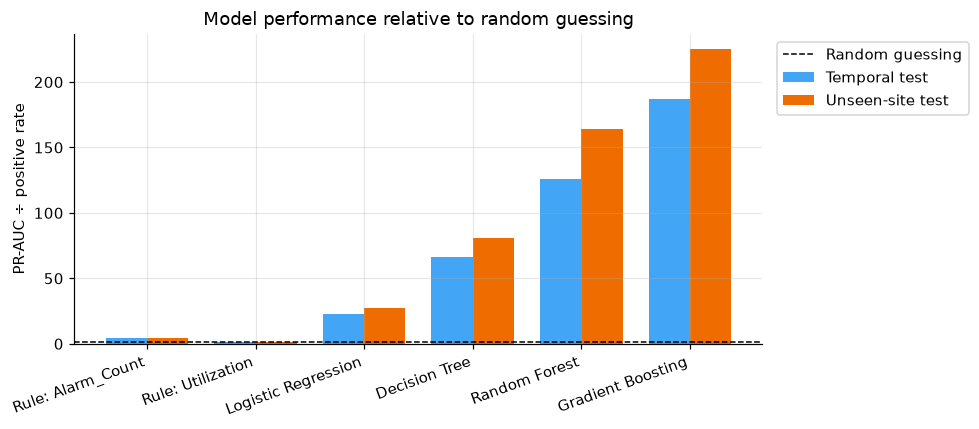

C:\Users\User\AppData\Local\Temp\ipykernel_26216\2137648553.py:79: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\User\AppData\Local\Temp\ipykernel_26216\2137648553.py:80: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


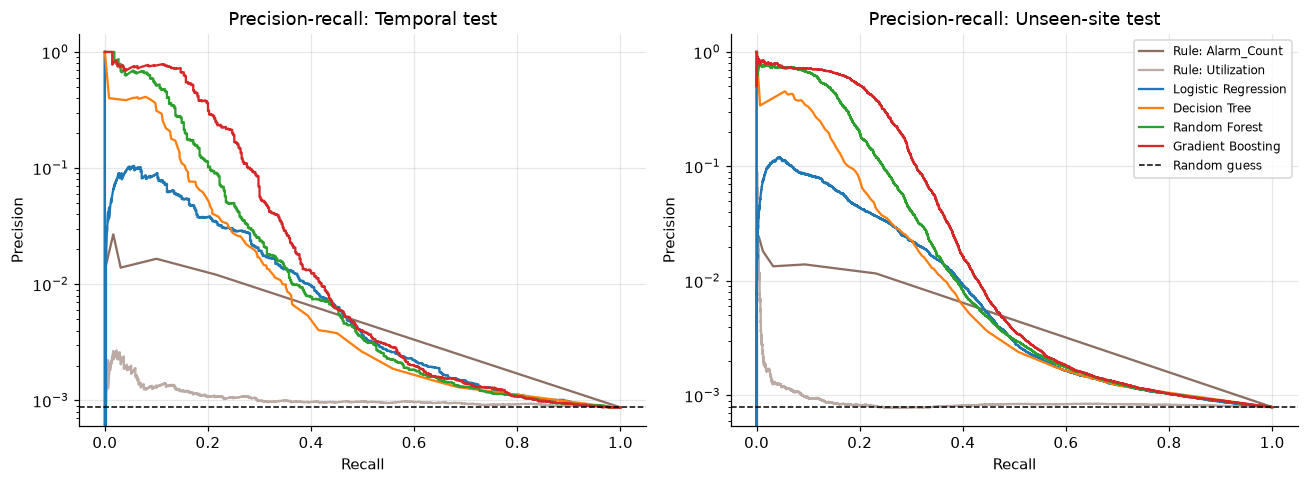

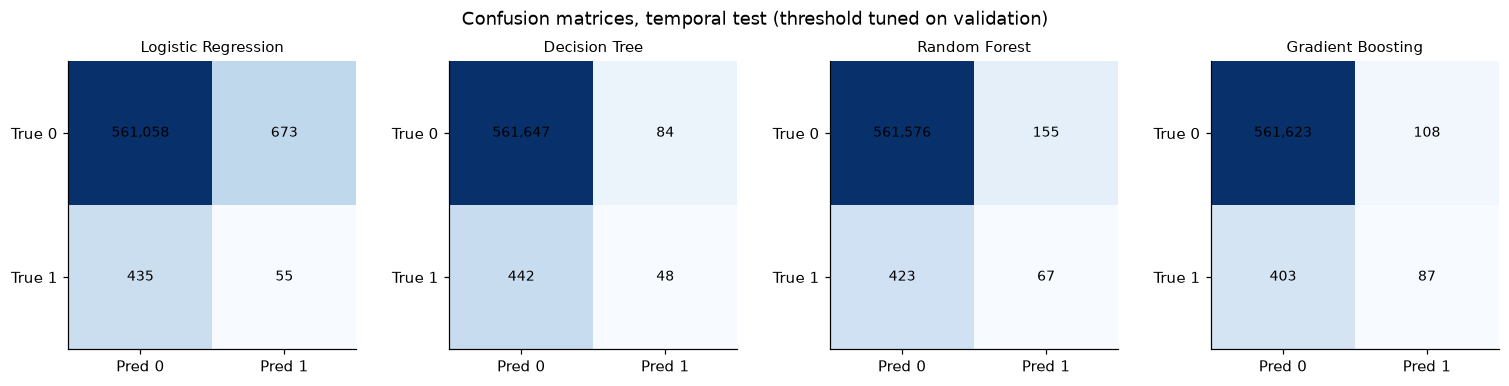

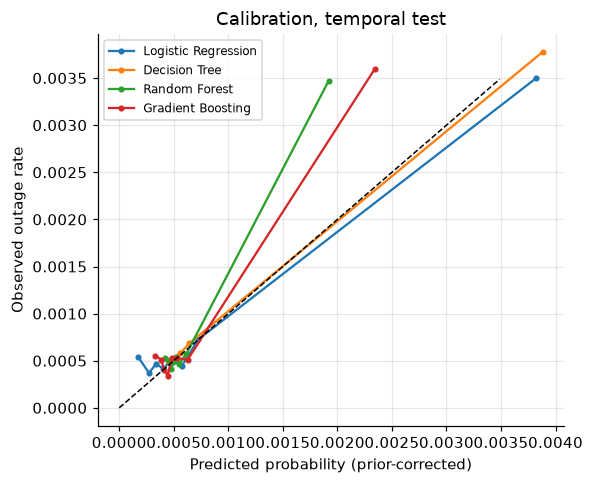

In [14]:
# Lift chart (PR-AUC / positive rate) on both test sets
order = ["Rule: Alarm_Count", "Rule: Utilization", "Logistic Regression", "Decision Tree", "Random Forest", "Gradient Boosting"]
fig, ax = plt.subplots(figsize=(9, 4))
w_ = 0.38
for i, es in enumerate(["Temporal test", "Unseen-site test"]):
    sub = RES[(RES["Eval set"] == es) & (RES.Features == "Full")].set_index("Model").reindex(order)
    ax.bar(np.arange(len(order)) + (i - 0.5) * w_, sub.Lift_vs_random, w_, label=es, color=["#42a5f5", "#ef6c00"][i])
ax.axhline(1, color="k", ls="--", lw=1, label="Random guessing")
ax.set_xticks(np.arange(len(order))); ax.set_xticklabels(order, rotation=20, ha="right")
ax.set_ylabel("PR-AUC ÷ positive rate"); ax.set_title("Model performance relative to random guessing")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
savefig("rq4_lift_vs_random")

# Precision-recall curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, es in zip(axes, ["Temporal test", "Unseen-site test"]):
    y = EVAL_SETS[es].y
    for nm in order:
        if y.sum() == 0:
            continue
        p, r, _ = precision_recall_curve(y, SCORES[(nm, "Full")][es])
        ax.plot(r, p, label=nm, color=MODEL_COLORS[nm], lw=1.5)
    ax.axhline(y.mean(), color="k", ls="--", lw=1, label="Random guess")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title(f"Precision-recall: {es}")
    ax.set_yscale("log")
axes[1].legend(fontsize=8)
savefig("rq4_precision_recall_curves")

# Confusion matrices at the validation-tuned threshold (temporal test)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, nm in zip(axes, ["Logistic Regression", "Decision Tree", "Random Forest", "Gradient Boosting"]):
    r_ = RES[(RES.Model == nm) & (RES.Features == "Full") & (RES["Eval set"] == "Temporal test")].iloc[0]
    cm = np.array([[r_.TN, r_.FP], [r_.FN, r_.TP]])
    ax.imshow(np.log1p(cm), cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{int(v):,}", ha="center", va="center", fontsize=9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred 0", "Pred 1"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["True 0", "True 1"])
    ax.set_title(nm, fontsize=10); ax.grid(False)
plt.suptitle("Confusion matrices, temporal test (threshold tuned on validation)")
savefig("rq4_confusion_matrices")

# Calibration (after prior correction), temporal test
plt.figure(figsize=(5.5, 4.5))
y = TT.y.to_numpy()
for nm in ["Logistic Regression", "Decision Tree", "Random Forest", "Gradient Boosting"]:
    if y.sum() < 5:
        break
    pc = calibrate(SCORES[(nm, "Full")]["Temporal test"])
    fr, mp = calibration_curve(y, pc, n_bins=8, strategy="quantile")
    plt.plot(mp, fr, marker="o", ms=3, label=nm, color=MODEL_COLORS[nm])
lim = [0, max(0.002, float(y.mean()) * 4)]
plt.plot(lim, lim, "k--", lw=1); plt.xlabel("Predicted probability (prior-corrected)"); plt.ylabel("Observed outage rate")
plt.title("Calibration, temporal test"); plt.legend(fontsize=8)
savefig("rq4_calibration")

In [15]:
# Seasonal and technology breakdown of the best model (lift vs. random)
rows = []
for es in ["Temporal test", "Unseen-site test"]:
    df = EVAL_SETS[es].assign(score=SCORES[(BEST, "Full")][es])
    df["Season"] = df.Month.map(SEASON_OF_MONTH); df["Technology"] = CELL_TECH[df.cell]
    for gcol in ["Season", "Technology"]:
        for g, d in df.groupby(gcol):
            if d.y.sum() == 0:
                continue
            ap = average_precision_score(d.y, d.score)
            rows.append({"Eval set": es, "Breakdown": gcol, "Group": g, "Rows": len(d), "Positives": int(d.y.sum()),
                         "Positive_rate_pct": 100 * d.y.mean(), "PR_AUC": ap, "Lift_vs_random": ap / d.y.mean()})
savetab(pd.DataFrame(rows).round(5), "rq4_best_model_by_season_technology")

,Eval set,Breakdown,Group,Rows,Positives,Positive_rate_pct,PR_AUC,Lift_vs_random
0,Temporal test,Season,Rainy,189441,171,0.09027,0.06183,68.49627
1,Temporal test,Season,Summer,189452,132,0.06967,0.27013,387.70218
2,Temporal test,Season,Winter,183328,187,0.10200,0.18978,186.05524
3,Temporal test,Technology,2G,151597,136,0.08971,0.12222,136.23996
4,Temporal test,Technology,3G,143498,109,0.07596,0.19574,257.69732
5,Temporal test,Technology,4G,150120,138,0.09193,0.19615,213.38240
6,Temporal test,Technology,5G,117006,107,0.09145,0.16393,179.25535
7,Unseen-site test,Season,Rainy,1891680,1536,0.08120,0.14468,178.18430
8,Unseen-site test,Season,Summer,1891723,1466,0.07750,0.21304,274.90261
9,Unseen-site test,Season,Winter,1830673,1443,0.07882,0.18171,230.53216


### 10.1 RQ5 — Do neighbor / same-site features help?  And where does any signal come from (ablation)?

In [16]:
fit_family(BEST, "KPI-only")
fit_family(BEST, "No-KPI")
rows = [evaluate(nm, fs, es) for (nm, fs) in FITTED if fs in ("KPI-only", "No-KPI") for es in EVAL_SETS]
RES = pd.concat([RES, pd.DataFrame(rows)], ignore_index=True)
RES.to_csv(TAB_DIR / "rq4_all_results.csv", index=False)
rq5 = RES[(~RES.Model.str.startswith("Rule")) & (RES.Model != "Random guess") & (RES["Eval set"] != "Validation")]
rq5 = rq5.pivot_table(index=["Model", "Eval set"], columns="Features", values="Lift_vs_random").reset_index()
savetab(rq5.round(3), "rq5_feature_set_comparison_lift")

# cascading check: how often a neighbor / same-site outage in the last 6 h precedes a positive vs. negative row
casc = []
for es in ["Temporal test", "Unseen-site test"]:
    df = EVAL_SETS[es]
    for f in NBR_FEATS[:2]:
        casc.append({"Eval set": es, "Feature": f, "Share_of_positive_rows_pct": 100 * (df.loc[df.y == 1, f] > 0).mean(),
                     "Share_of_negative_rows_pct": 100 * (df.loc[df.y == 0, f] > 0).mean()})
savetab(pd.DataFrame(casc).round(3), "rq5_cascading_check")

Gradient Boosting    [KPI-only     ] best {'learning_rate': 0.1, 'max_leaf_nodes': 31}  val PR-AUC=0.13117  thr=0.9093  fit=34s
Gradient Boosting    [No-KPI       ] best {'learning_rate': 0.1, 'max_leaf_nodes': 31}  val PR-AUC=0.00072  thr=0.0092  fit=36s


Features,Model,Eval set,Full,Full+Neighbor,KPI-only,No-KPI
0,Decision Tree,Temporal test,65.970,65.970,NaN,NaN
1,Decision Tree,Unseen-site test,81.007,81.007,NaN,NaN
2,Gradient Boosting,Temporal test,186.775,182.503,193.248,0.937
3,Gradient Boosting,Unseen-site test,225.297,226.335,230.620,0.976
4,Logistic Regression,Temporal test,22.713,27.385,NaN,NaN
5,Logistic Regression,Unseen-site test,27.688,35.071,NaN,NaN
6,Random Forest,Temporal test,125.606,125.677,NaN,NaN
7,Random Forest,Unseen-site test,164.211,163.447,NaN,NaN


,Eval set,Feature,Share_of_positive_rows_pct,Share_of_negative_rows_pct
0,Temporal test,Nbr_Outage_Starts_6h,0.204,0.394
1,Temporal test,Site_Outage_Starts_6h,0.000,0.124
2,Unseen-site test,Nbr_Outage_Starts_6h,0.427,0.386
3,Unseen-site test,Site_Outage_Starts_6h,0.202,0.113


## 11. Discussion — interpretability and complexity (guideline item 7)

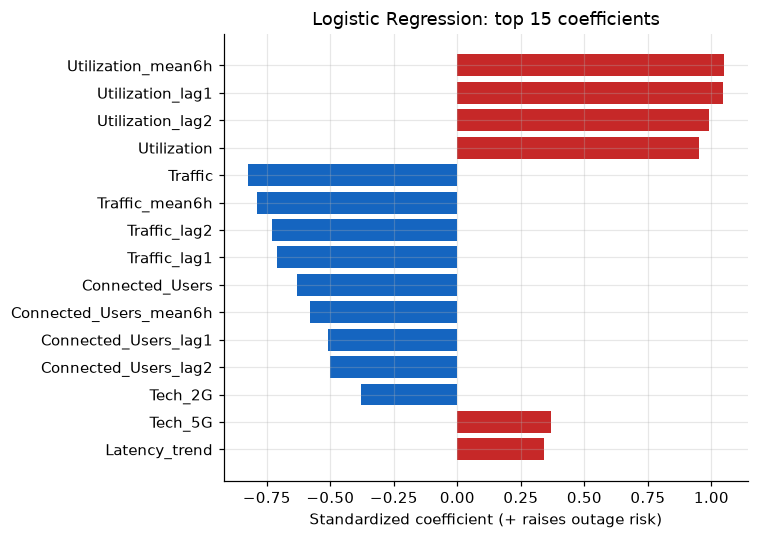

|--- Alarm_Count <= 0.50
|   |--- Latency <= 182.05
|   |   |--- Alarm_Count_mean6h <= 0.17
|   |   |   |--- Latency_trend <= 9.36
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- Latency_trend >  9.36
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- Alarm_Count_mean6h >  0.17
|   |   |   |--- Latency_trend <= 9.05
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- Latency_trend >  9.05
|   |   |   |   |--- truncated branch of depth 5
|   |--- Latency >  182.05
|   |   |--- Latency_lag1 <= 172.64
|   |   |   |--- Connected_Users <= 72.50
|   |   |   |   |--- class: 1
|   |   |   |--- Connected_Users >  72.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- Latency_lag1 >  172.64
|   |   |   |--- Connected_Users_lag1 <= 80.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- Connected_Users_lag1 >  80.50
|   |   |   |   |--- class: 1
|--- Alarm_Count >  0.50
|   |--- Alarm_Count_lag1 <= 0.50
|   |   |--- Latency_t

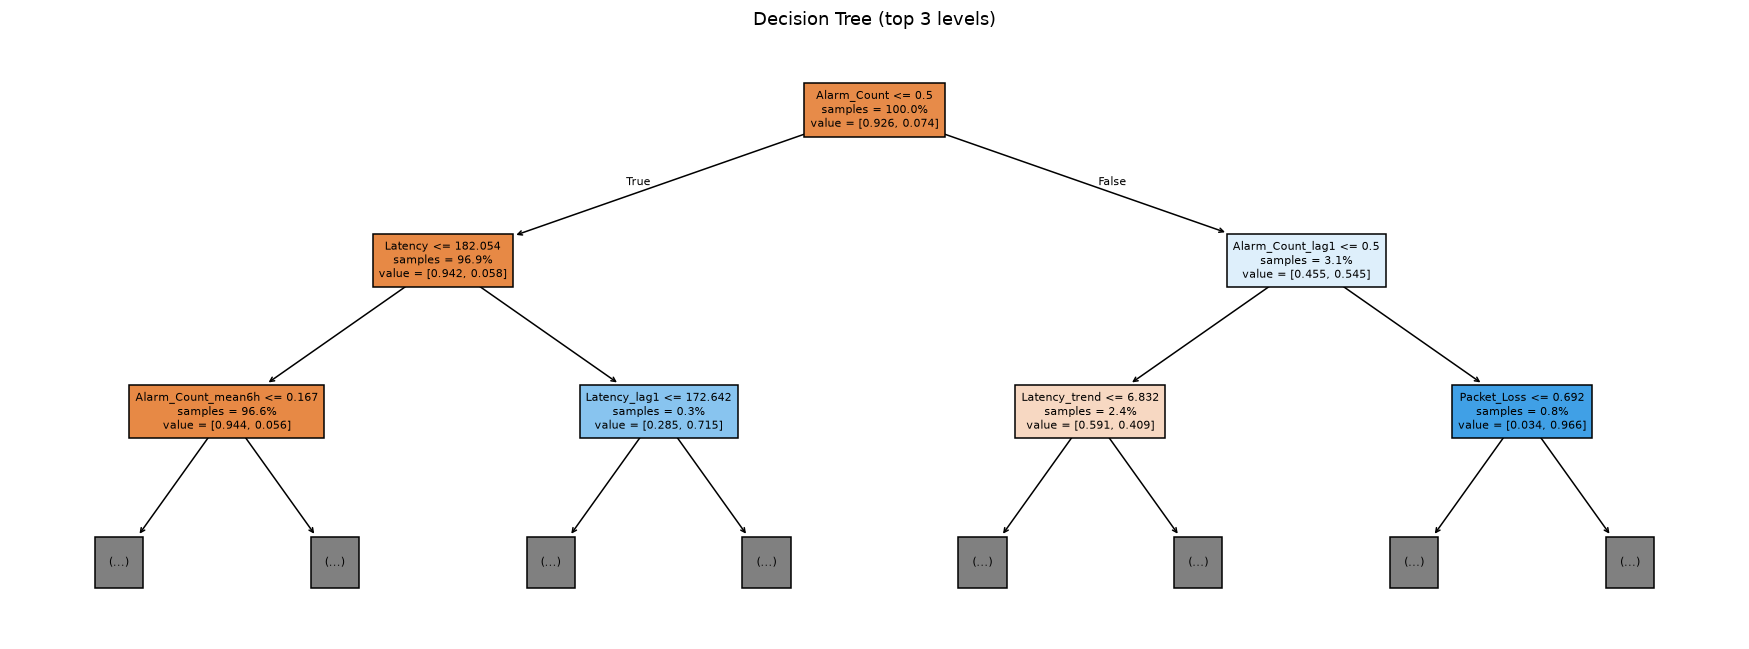

,Model,Feature,Group,Importance,Std
96,Gradient Boosting,Utilization,KPI lookback,0.196269,0.003793
80,Gradient Boosting,Latency_trend,KPI lookback,0.111726,0.001381
61,Gradient Boosting,Traffic,KPI lookback,0.098073,0.002497
94,Gradient Boosting,Alarm_Count_mean6h,KPI lookback,0.093981,0.002136
85,Gradient Boosting,Packet_Loss_trend,KPI lookback,0.086118,0.003583
98,Gradient Boosting,Utilization_lag2,KPI lookback,0.083903,0.002683
66,Gradient Boosting,Connected_Users,KPI lookback,0.059185,0.002868
99,Gradient Boosting,Utilization_mean6h,KPI lookback,0.030211,0.004906
81,Gradient Boosting,Packet_Loss,KPI lookback,0.028378,0.001025
91,Gradient Boosting,Alarm_Count,KPI lookback,0.025026,0.002741


Model,Group,Gradient Boosting,Random Forest
0,Calendar/context,0.015473,0.003643
1,KPI lookback,0.978143,0.197913
2,Outage history,-0.000688,0.000435


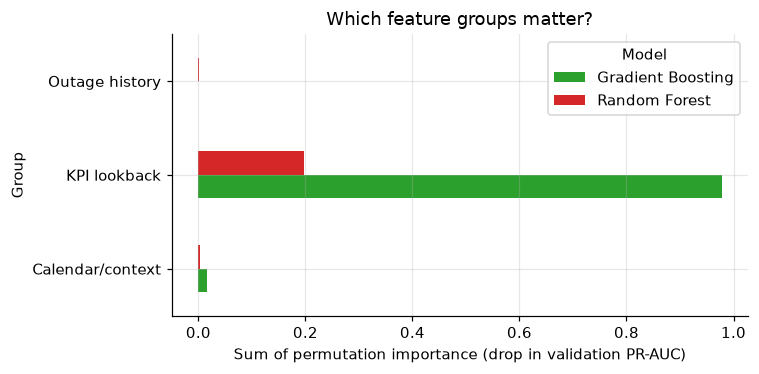

In [17]:
# Logistic Regression coefficients (standardized features)
lr = FITTED[("Logistic Regression", "Full")]
coef = pd.DataFrame({"Feature": lr["feats"], "Coefficient": lr["model"].named_steps["clf"].coef_[0]})
coef["Abs"] = coef.Coefficient.abs()
coef = coef.sort_values("Abs", ascending=False).head(15)
savetab(coef.drop(columns="Abs").round(4), "discussion_lr_top_coefficients", show=False)
plt.figure(figsize=(7, 5))
plt.barh(coef.Feature[::-1], coef.Coefficient[::-1], color=np.where(coef.Coefficient[::-1] > 0, "#c62828", "#1565c0"))
plt.xlabel("Standardized coefficient (+ raises outage risk)"); plt.title("Logistic Regression: top 15 coefficients")
savefig("discussion_lr_coefficients")

# Decision Tree rules (top levels)
dt_ = FITTED[("Decision Tree", "Full")]
rules_txt = export_text(dt_["model"].named_steps["clf"], feature_names=dt_["feats"], max_depth=3)
(TAB_DIR / "discussion_decision_tree_rules.txt").write_text(rules_txt)
print(rules_txt[:3000])
plt.figure(figsize=(16, 6))
plot_tree(dt_["model"].named_steps["clf"], feature_names=dt_["feats"], max_depth=2, filled=True, fontsize=7, impurity=False,
          proportion=True)
plt.title("Decision Tree (top 3 levels)")
savefig("discussion_decision_tree")

# Permutation importance (validation subsample: all positives + up to 50,000 negatives), PR-AUC scoring
sub = pd.concat([VA[VA.y == 1], VA[VA.y == 0].sample(n=min(50_000, int((VA.y == 0).sum())), random_state=SEED)])
imp_rows = []
for nm in ["Random Forest", "Gradient Boosting"]:
    f_ = FITTED[(nm, "Full")]
    if sub.y.sum() == 0:
        break
    pi = permutation_importance(f_["model"], sub[f_["feats"]], sub.y, scoring="average_precision", n_repeats=3,
                                random_state=SEED, n_jobs=1)
    for f, m_, s_ in zip(f_["feats"], pi.importances_mean, pi.importances_std):
        imp_rows.append({"Model": nm, "Feature": f, "Group": FEATURE_GROUP[f], "Importance": m_, "Std": s_})
IMP = pd.DataFrame(imp_rows)
if len(IMP):
    savetab(IMP.sort_values(["Model", "Importance"], ascending=[True, False]).groupby("Model").head(10).round(6),
            "discussion_permutation_importance_top10")
    grp = IMP.groupby(["Model", "Group"]).Importance.sum().unstack(0)
    savetab(grp.reset_index().round(6), "discussion_importance_by_group")
    grp.plot(kind="barh", figsize=(7, 3.5), color=["#2ca02c", "#d62728"])
    plt.xlabel("Sum of permutation importance (drop in validation PR-AUC)"); plt.title("Which feature groups matter?")
    savefig("discussion_importance_by_group")

In [18]:
# Complexity comparison
def n_params(nm, mdl):
    if nm == "Logistic Regression":
        return int(mdl.named_steps["clf"].coef_.size + 1)
    if nm == "Decision Tree":
        return int(mdl.named_steps["clf"].tree_.node_count)
    if nm == "Random Forest":
        return int(sum(e.tree_.node_count for e in mdl.named_steps["clf"].estimators_))
    if nm == "Gradient Boosting":
        return int(sum(p.nodes.shape[0] for it in mdl._predictors for p in it))
    return 1

INTERP = {"Rule: Alarm_Count": "Very high (one threshold)", "Rule: Utilization": "Very high (one threshold)",
          "Logistic Regression": "High (signed coefficients)", "Decision Tree": "High (readable if-then rules)",
          "Random Forest": "Medium-low (needs feature importance)", "Gradient Boosting": "Low (needs feature importance)"}
cx = []
for nm in order:
    f_ = FITTED[(nm, "Full")]
    r_t = RES[(RES.Model == nm) & (RES.Features == "Full") & (RES["Eval set"] == "Temporal test")].iloc[0]
    r_u = RES[(RES.Model == nm) & (RES.Features == "Full") & (RES["Eval set"] == "Unseen-site test")].iloc[0]
    cx.append({"Model": nm, "Hyper-parameters": str(f_["params"]),
               "Parameters_or_nodes": n_params(nm, f_["model"]) if f_["model"] is not None else 1,
               "Model_size_KB": round(len(pickle.dumps(f_["model"])) / 1024, 1) if f_["model"] is not None else 0,
               "Fit_time_s": round(f_["fit_s"], 1), "Predict_s_per_1M_rows": round(f_["pred_s_per_1M"], 2),
               "Interpretability": INTERP[nm], "Lift_temporal": round(r_t.Lift_vs_random, 3),
               "Lift_unseen": round(r_u.Lift_vs_random, 3), "Recall_temporal": round(r_t.Recall, 4),
               "FA_per_site_day_temporal": round(r_t.False_alarms_per_site_day, 4)})
COMPLEXITY = pd.DataFrame(cx)
savetab(COMPLEXITY, "discussion_performance_interpretability_complexity")
RESULTS["complexity"] = COMPLEXITY.to_dict(orient="records")

if SAVE_MODELS:
    for (nm, fs), f_ in FITTED.items():
        if f_["model"] is not None and fs in ("Full", "Full+Neighbor"):
            pickle.dump({"model": f_["model"], "features": f_["feats"], "threshold": f_["thr"]},
                        open(MODEL_DIR / f"{nm.replace(' ', '_')}__{fs.replace('+', '_')}.pkl", "wb"))

,Model,Hyper-parameters,Parameters_or_nodes,Model_size_KB,Fit_time_s,Predict_s_per_1M_rows,Interpretability,Lift_temporal,Lift_unseen,Recall_temporal,FA_per_site_day_temporal
0,Rule: Alarm_Count,{'threshold': 3.0},1,0.0,0.0,0.00,Very high (one threshold),4.420,4.528,0.0306,0.0163
1,Rule: Utilization,{'threshold': 300.47418212890625},1,0.0,0.0,0.00,Very high (one threshold),1.235,1.325,0.0163,0.0464
2,Logistic Regression,{'C': 1.0},62,4.3,5.1,0.72,High (signed coefficients),22.713,27.688,0.1122,0.0103
3,Decision Tree,"{'max_depth': 8, 'min_samples_leaf': 200}",179,16.8,22.4,0.59,High (readable if-then rules),65.970,81.007,0.0980,0.0013
4,Random Forest,"{'max_depth': 14, 'min_samples_leaf': 50}",219500,17213.3,427.8,12.26,Medium-low (needs feature importance),125.606,164.211,0.1367,0.0024
5,Gradient Boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 31}",18300,1123.1,74.1,14.93,Low (needs feature importance),186.775,225.297,0.1776,0.0017


## 12. Comparison with public Kaggle / Hugging Face work (guideline: "how the system compares with others")
Scores from different datasets are **not directly comparable**, so the comparison is about task design, leakage control, evaluation
and usefulness to an operations team.

| Aspect | Kaggle *Telstra Network Disruptions* (2015-16) | Hugging Face *TelecomTS* (5G testbed, 2025) | Typical KPI-monitor demos (GitHub/Kaggle) | **This project** |
|---|---|---|---|---|
| Task | Classify fault severity (0/1/2) of an already-logged disruption at a location | Anomaly detection / forecasting on 10 Hz KPI windows | Anomaly or coverage classification, often accuracy-only | **Forecast** a new outage of a cell in the next 12 h |
| Time awareness | Random train/test split by location-time id; no forecast horizon | Fixed sample windows | Usually random splits | Chronological seasonal split + **2,000 unseen sites** |
| Leakage control | Top solutions used target-dependent location features | n/a | Rarely discussed | Event-time labels, past-only features, preprocessing fit on train only |
| Metric | Multi-class log-loss | Forecast / detection scores | Accuracy (e.g., ~99 %) | PR-AUC vs. random, recall, precision, F1, **false alarms per site-day, lead time, calibration** |
| Network context | Location id only | Single testbed | Single cell / no topology | Neighbor & same-site features, **outage impact on neighbors**, network availability |
| Interpretability | Gradient-boosted ensembles | Deep models | Varies | LR coefficients, tree rules, permutation importance, rule baselines |

**Unique features / user benefits:** (1) answers an operational question (which cells will fail in the next 12 h, and with how many
false alarms per site per day); (2) honest evaluation that would expose leakage instead of hiding it; (3) neighbor-impact
quantification shows operators where load moves during an outage; (4) a light, reproducible Python pipeline that streams ~134 M rows
on a laptop; (5) the model must beat a tuned rule an engineer could deploy today, otherwise it is not recommended.

## 13. Conclusions — auto-generated summary of the results (guideline item 8)

In [19]:
def g(es, nm, col, fs="Full"):
    r_ = RES[(RES.Model == nm) & (RES.Features == fs) & (RES["Eval set"] == es)]
    return float(r_[col].iloc[0]) if len(r_) else float("nan")

best_lift_t, best_lift_u = g("Temporal test", BEST, "Lift_vs_random"), g("Unseen-site test", BEST, "Lift_vs_random")
rule_lift_t = max(g("Temporal test", "Rule: Alarm_Count", "Lift_vs_random"), g("Temporal test", "Rule: Utilization", "Lift_vs_random"))
nbr_gain = g("Temporal test", BEST, "Lift_vs_random", "Full+Neighbor") - best_lift_t
summary = f"""
Data file: {DATASET_2_FILE.name}
RQ1  Data pipeline: {CNT_A['rows']:,} Dataset-2 rows validated ({CNT_A['kpi_rows']:,} KPI, {CNT_A['outage_rows']:,} OUTAGE,
     {CNT_A['recovery_rows']:,} RECOVERY); {CNT_A['unparsed_timestamp']:,} unparseable timestamps; {CNT_A['duplicate_kpi_keys']:,}
     duplicate KPI keys; model-ready table of {N_MODEL_ROWS:,} rows with {len(FEATURE_SETS['Full+Neighbor'])} leakage-safe features.
RQ2  Network availability {RESULTS['network_availability_pct']}% over the study period; median share of a failed cell's users
     absorbed by neighbors: {RESULTS['neighbor_users_absorbed_median_pct']}%; total estimated user-hours lost:
     {RESULTS['service_impact_total_user_hours_lost']:,}.
RQ3  Share of outages with a higher KPI value in the 12 h before (vs. 7 days earlier): {RESULTS['rq3_share_higher_range_pct'][0]}-
     {RESULTS['rq3_share_higher_range_pct'][1]}%; smallest Wilcoxon p = {RESULTS['rq3_min_wilcoxon_p']:.3g}.
RQ4  Best model on validation: {BEST}. Lift vs. random (PR-AUC / positive rate): temporal test {best_lift_t:.2f},
     unseen-site test {best_lift_u:.2f}; best rule baseline (temporal) {rule_lift_t:.2f}.
     Recall {g('Temporal test', BEST, 'Recall'):.3f}, precision {g('Temporal test', BEST, 'Precision'):.4f},
     false alarms / site-day {g('Temporal test', BEST, 'False_alarms_per_site_day'):.3f},
     median lead time {g('Temporal test', BEST, 'Median_lead_time_h'):.1f} h.
RQ5  Adding neighbor/same-site features changes the temporal-test lift by {nbr_gain:+.2f}.
"""
print(summary)
interpretation = ("A lift close to 1.0 means the KPIs carry no usable early-warning signal in this dataset (as found in the progress "
                  "report); the leakage-safe design is what makes this visible." if best_lift_t < 1.5 else
                  "A lift well above 1.0 on BOTH the later months and the unseen sites means the model generalizes in time and space.")
print("Interpretation:", interpretation)
(OUT_DIR / "results_summary.txt").write_text(summary + "\nInterpretation: " + interpretation)
RESULTS["summary_text"] = summary
RESULTS["run_finished"] = time.strftime("%Y-%m-%d %H:%M")
json.dump(RESULTS, open(OUT_DIR / "results_summary.json", "w"), indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("All tables:", TAB_DIR, "\nAll figures:", FIG_DIR)


Data file: Dataset_2_Marge_V4.csv
RQ1  Data pipeline: 133,952,650 Dataset-2 rows validated (133,899,043 KPI, 26,809 OUTAGE,
     26,798 RECOVERY); 0 unparseable timestamps; 0
     duplicate KPI keys; model-ready table of 7,201,898 rows with 65 leakage-safe features.
RQ2  Network availability 99.9849% over the study period; median share of a failed cell's users
     absorbed by neighbors: 28.2%; total estimated user-hours lost:
     6,762,258.1.
RQ3  Share of outages with a higher KPI value in the 12 h before (vs. 7 days earlier): 23.6-
     75.6%; smallest Wilcoxon p = 0.
RQ4  Best model on validation: Gradient Boosting. Lift vs. random (PR-AUC / positive rate): temporal test 186.77,
     unseen-site test 225.30; best rule baseline (temporal) 4.42.
     Recall 0.178, precision 0.4462,
     false alarms / site-day 0.002,
     median lead time 4.8 h.
RQ5  Adding neighbor/same-site features changes the temporal-test lift by -4.27.

Interpretation: A lift well above 1.0 on BOTH the later 

### Contributions (for the report and the final slide)
1. A **leakage-safe, reproducible Python pipeline** that validates, deduplicates and links two telecom datasets (~134 M rows) on a
   laptop with chunked streaming, ISO 8601 parsing and row-count checks.
2. **Three-level outage impact analysis**: affected-cell service loss, neighbor difference-in-differences (same-site vs. other-site),
   and network availability by technology, month and season.
3. A **pre-modeling signal test** (matched-control Wilcoxon) that checks whether prediction is possible before any model is trusted.
4. A **fair benchmark** of Logistic Regression (baseline), Decision Tree, Random Forest and Gradient Boosting against tuned rules,
   with chronological + unseen-site testing and operational metrics (false alarms per site-day, lead time, calibration).
5. An **RQ5 neighbor-feature experiment** and an interpretability/complexity comparison to guide which model an operator should use.